# H14 — Cell-Marker-Derived Follicle & PALS Boundaries (v2)

**Goal:** Derive follicle and PALS boundaries from single-cell CD20 (B-cell) and CD3e (T-cell)
expression in `Cells.csv`, replacing platform-dependent pixel-classifier boundaries.

**v2 changes:**
- **Percentile thresholding** (top 10%, p90) replaces Otsu — platform-invariant
- **Per-image adaptive bandwidth** from k-NN distances — sharper boundaries where cells cluster tightly
- **5000x3000 um rectangular crop** matches CODEX tissue dimensions
- **Vessel area fraction** (dimensionless) replaces count-based density
- **LargeVessel exclusion** — arterioles (visible lumen + smooth muscle) subtracted from region area denominator, as they share CD31/CD34 markers with SmallVessels but are not microvessels
- Uses `AnnotationsFinal.csv` (13 images including HDL079; corrected 1901HBMP004 LargeVessel classifications)
- **KDE grid padding** (2xBW per image) eliminates straight-line edge artifacts

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle, Patch, PathPatch
from matplotlib.path import Path as MplPath
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu
from shapely.affinity import scale as shapely_scale
from shapely.geometry import Polygon, shape
from shapely.ops import unary_union
from shapely.validation import make_valid

from data_utils import (
    PROJECT, FIGURES_DIR, TABLES_DIR,
    GENO_ORDER, GENO_PALETTE, MAIN_REGIONS,
    EXCLUDE_SAMPLES, GENOTYPE_MAP, CODEX_SAMPLES,
    extract_sample_id, get_vessels, get_regions,
    full_stats_table, setup_style, save_figure, save_table,
    compute_marker_kde, extract_region_polygons, assign_objects_to_polygons,
    load_region_layer, load_clinical,
)

warnings.filterwarnings("ignore", category=FutureWarning)
setup_style()

In [2]:
ANNOT_CSV = PROJECT / "Measurements" / "AnnotationsFinal.csv"
CELLS_CSV = PROJECT / "Measurements" / "Cells.csv"

# ── Cropping is DISABLED: Phenocycler sections are analysed whole ──
# Cropping them to a CODEX-sized window was a mitigation for the ~10x difference
# in imaged area. It is abandoned. It discarded 75-88% of the data to address
# only the first of the four confound mechanisms — unequal effort — and left
# field selection, optical resolution and detection sensitivity untouched. A
# larger section yields a more precise estimate, not a biased one; H20's
# count-rate model with an area offset is the replacement.
#
# The thresholds are pushed beyond any real extent rather than deleted, so the
# machinery below still runs and returns "no crop" for every sample. That keeps
# the downstream guards exercised rather than leaving dead branches behind.
CROP_W, CROP_H = 5000, 3000          # µm — kept for the context figures only
CROP_THRESHOLD_X = np.inf
CROP_THRESHOLD_Y = np.inf

GRID_SPACING = 10                     # µm per KDE grid cell
MIN_AREA_UM2 = 8400                   # min polygon area (from H6 GMM)

# ── Marker-specific percentile & contour thresholds ──
# CD20+ B-cells cluster tightly in follicles → moderate threshold works.
# CD3e+ T-cells are diffuse → need stricter selection AND higher contour cutoff.
CD20_PERCENTILE = 90                  # top 10% — follicle B-cells
CD3E_PERCENTILE = 95                  # top 5%  — PALS T-cells (more diffuse)
CD20_THRESHOLD_FRAC = 0.10            # contour at 10% of max KDE density
CD3E_THRESHOLD_FRAC = 0.25            # contour at 25% — only densest T-cell cores

# ── Adaptive bandwidth parameters ──
BW_K = 5                              # k-th nearest neighbor for NND
NND_SCALE = 4                         # BW = NND_SCALE × median k-NN distance
BW_MIN, BW_MAX = 25, 100             # clamp range (µm)

def adaptive_bandwidth(coords, k=BW_K, scale=NND_SCALE,
                       bw_min=BW_MIN, bw_max=BW_MAX):
    """Per-image bandwidth from k-NN distances of marker-positive cells."""
    if len(coords) < k + 1:
        return (bw_min + bw_max) / 2   # fallback
    tree = cKDTree(coords)
    dists, _ = tree.query(coords, k=k + 1)   # k+1: index 0 is self
    median_knn = np.median(dists[:, k])       # k-th neighbor distance
    return float(np.clip(median_knn * scale, bw_min, bw_max))

CD20_COL = "Cell: CD20: Mean"
CD3E_COL = "Cell: CD3e: Mean"
X_COL, Y_COL = "Centroid X µm", "Centroid Y µm"
USE_COLS = ["Image", X_COL, Y_COL, CD20_COL, CD3E_COL]

HIST_BINS = 2000
HIST_RANGE = (0, 65000)

# The pixel-classifier reference geometry now comes from the region layer,
# which is already in µm and already area-filtered. The local pixel-size table
# that used to live here shadowed data_utils.get_pixel_size and omitted the
# three ForSH2B3 CODEX sections, rescaling them at 0.5078 instead of 0.3774.

print(f"Data: {ANNOT_CSV.name}")
print(f"Cropping: DISABLED (full sections) | KDE grid: {GRID_SPACING} µm")
print(f"CD20 (Follicle): p{CD20_PERCENTILE} → contour at {CD20_THRESHOLD_FRAC:.0%} of max")
print(f"CD3e (PALS):     p{CD3E_PERCENTILE} → contour at {CD3E_THRESHOLD_FRAC:.0%} of max")
print(f"Adaptive BW: k={BW_K}, scale={NND_SCALE}×, range=[{BW_MIN}, {BW_MAX}] µm")

Data: AnnotationsFinal.csv
Cropping: DISABLED (full sections) | KDE grid: 10 µm
CD20 (Follicle): p90 → contour at 10% of max
CD3e (PALS):     p95 → contour at 25% of max
Adaptive BW: k=5, scale=4×, range=[25, 100] µm


In [3]:
# Load AnnotationsFinal.csv directly (not load_data which uses the old DATA_CSV path)
df_all = pd.read_csv(ANNOT_CSV)
df_all["Sample"] = df_all["Image"].apply(extract_sample_id)
df_all["Genotype"] = df_all["Sample"].map(GENOTYPE_MAP)
df_all = df_all[~df_all["Sample"].isin(EXCLUDE_SAMPLES)]
df_all = df_all.dropna(subset=["Genotype"])
df_all["Genotype"] = pd.Categorical(df_all["Genotype"], categories=GENO_ORDER, ordered=True)
df_all["Platform"] = df_all["Sample"].apply(
    lambda s: "CODEX" if s in CODEX_SAMPLES else "Phenocycler")

analysis_images = set(df_all["Image"].unique())
img_to_sample = df_all.drop_duplicates("Image").set_index("Image")["Sample"].to_dict()
print(f"Loaded {len(df_all):,} annotations, {df_all['Sample'].nunique()} samples")
print(f"Samples: {sorted(df_all['Sample'].unique())}")

# ── Rectangular crop windows centred on tissue median ──
# Uses median centroid of ALL annotations (unbiased — not vessel-maximising)
# then clamps to keep the window within the tissue bounding box.
# Manual overrides for samples where median falls on empty space (e.g. split tissue).
CROP_OVERRIDES = {
    "HDL011": (2000, 2000),  # two-piece tissue; shift right+down onto lower fragment
}
half_w, half_h = CROP_W / 2, CROP_H / 2

crop_windows = {}  # sample -> (cx, cy) or None
for sample in sorted(df_all["Sample"].unique()):
    sdf = df_all[df_all["Sample"] == sample]
    coords = sdf[[X_COL, Y_COL]].values
    x_ext, y_ext = np.ptp(coords[:, 0]), np.ptp(coords[:, 1])

    if x_ext <= CROP_THRESHOLD_X and y_ext <= CROP_THRESHOLD_Y:
        crop_windows[sample] = None
        continue

    # Median centroid of all annotations — robust, region-agnostic
    cx = np.median(coords[:, 0])
    cy = np.median(coords[:, 1])

    # Apply manual offset if needed
    if sample in CROP_OVERRIDES:
        dx, dy = CROP_OVERRIDES[sample]
        cx += dx
        cy += dy

    # Clamp so the window stays within the data extent
    cx = np.clip(cx, coords[:, 0].min() + half_w, coords[:, 0].max() - half_w)
    cy = np.clip(cy, coords[:, 1].min() + half_h, coords[:, 1].max() - half_h)

    crop_windows[sample] = (cx, cy)

# Apply crop vectorised
keep = np.ones(len(df_all), dtype=bool)
for sample, window in crop_windows.items():
    if window is None:
        continue
    cx, cy = window
    mask_s = df_all["Sample"].values == sample
    keep[mask_s] &= (
        (np.abs(df_all.loc[mask_s, X_COL].values - cx) <= half_w) &
        (np.abs(df_all.loc[mask_s, Y_COL].values - cy) <= half_h))
df_crop = df_all[keep].copy()

print(f"\nAnnotations analysed: {len(df_crop):,} (full extent)")
for s in sorted(df_crop["Sample"].unique()):
    nb, na = (df_all["Sample"] == s).sum(), (df_crop["Sample"] == s).sum()
    tag = "full" if crop_windows.get(s) is None else "crop"
    override = " (manual offset)" if s in CROP_OVERRIDES else ""
    print(f"  {s:16s} {na:6d}/{nb:6d}  ({tag}{override})")

Loaded 440,826 annotations, 11 samples
Samples: ['1901HBMP004', 'HDL011', 'HDL043', 'HDL052', 'HDL053', 'HDL055', 'HDL063', 'HDL070', 'HDL073', 'HDL079', 'HDL086']



Annotations analysed: 440,826 (full extent)
  1901HBMP004        4813/  4813  (full)
  HDL011            34567/ 34567  (full (manual offset))


  HDL043            29559/ 29559  (full)
  HDL052            16426/ 16426  (full)
  HDL053            71018/ 71018  (full)
  HDL055            71143/ 71143  (full)


  HDL063            90676/ 90676  (full)
  HDL070            32597/ 32597  (full)
  HDL073             5108/  5108  (full)
  HDL079            40169/ 40169  (full)


  HDL086            44750/ 44750  (full)


In [4]:
# ── Load Cells.csv with pyarrow (no chunking — 512GB RAM) ──
cells = pd.read_csv(CELLS_CSV, usecols=USE_COLS, engine='pyarrow')
n_total = len(cells)

# Keep only analysis images
cells = cells[cells["Image"].isin(analysis_images)].copy()
cells["Sample"] = cells["Image"].map(img_to_sample)

# Apply crop windows
keep = np.ones(len(cells), dtype=bool)
for sample, window in crop_windows.items():
    if window is None:
        continue
    cx, cy = window
    mask = cells["Sample"].values == sample
    if not mask.any():
        continue
    keep[mask] &= (
        (np.abs(cells.loc[mask, X_COL].values - cx) <= half_w) &
        (np.abs(cells.loc[mask, Y_COL].values - cy) <= half_h))

cells = cells[keep].reset_index(drop=True)

print(f"Total rows loaded: {n_total:,}")
print(f"After image filter: {len(cells):,} cells (no cropping)")
for sample in sorted(cells["Sample"].unique()):
    print(f"  {sample:16s} {(cells['Sample'] == sample).sum():10,}")

# ── Pass 1: per-image intensity histograms → percentile thresholds ──
histograms = {}
bin_edges = np.linspace(HIST_RANGE[0], HIST_RANGE[1], HIST_BINS + 1)

for image, grp in cells.groupby("Image"):
    n = len(grp)
    h = {"cd20": np.zeros(HIST_BINS, dtype=np.int64),
         "cd3e": np.zeros(HIST_BINS, dtype=np.int64), "n": n}
    for col, key in [(CD20_COL, "cd20"), (CD3E_COL, "cd3e")]:
        vals = grp[col].dropna().values
        h[key] = np.histogram(vals, bins=bin_edges)[0]
    histograms[image] = h

# Compute per-marker percentile from cumulative histogram
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
percentile_thresholds = {}
_marker_pctls = {"cd20": CD20_PERCENTILE, "cd3e": CD3E_PERCENTILE}

print(f"\n{'Sample':16s} {'CD20_p'+str(CD20_PERCENTILE):>10s} "
      f"{'CD3e_p'+str(CD3E_PERCENTILE):>10s} {'N_cells':>10s}")
for image in sorted(histograms.keys()):
    sid = img_to_sample[image]
    h = histograms[image]
    thr = {}
    for key in ["cd20", "cd3e"]:
        cumsum = np.cumsum(h[key])
        total = cumsum[-1]
        if total == 0:
            thr[key] = np.inf
            continue
        idx = np.searchsorted(cumsum, total * _marker_pctls[key] / 100)
        thr[key] = bin_centers[min(idx, len(bin_centers) - 1)]
    percentile_thresholds[image] = thr
    print(f"  {sid:16s} {thr['cd20']:10.1f} {thr['cd3e']:10.1f} {h['n']:10,}")

Total rows loaded: 22,645,935
After image filter: 20,798,810 cells (no cropping)


  1901HBMP004         287,017
  HDL011            1,807,787


  HDL043            2,907,957
  HDL052              933,587


  HDL053            2,915,781
  HDL055            2,114,146


  HDL063            3,744,062
  HDL070            1,651,718


  HDL073              270,608
  HDL079            1,652,806


  HDL086            2,513,341



Sample             CD20_p90   CD3e_p95    N_cells
  1901HBMP004          6028.8     1088.8    287,017
  HDL011               1023.8     2583.8  1,807,787
  HDL043               1153.8     2291.2  2,907,957
  HDL052                373.8     1543.8    933,587
  HDL053               2356.2     3331.2  2,915,781
  HDL055               1218.8     1446.2  2,114,146
  HDL063                828.8     1706.2  3,744,062
  HDL070               1576.2     3298.8  1,651,718
  HDL073               9506.2     8726.2    270,608
  HDL079               1478.8     2063.8  1,652,806
  HDL086               1218.8     1738.8  2,513,341


In [5]:
# Pass 2: extract marker-positive coordinates using percentile thresholds
# (reuses `cells` DataFrame loaded in previous cell)
cd20_coords = {}
cd3e_coords = {}
cell_xy = {}
raw_cell_data = {}  # {image: (N,4) array [x, y, cd20, cd3e]} for sensitivity reuse

for image, grp in cells.groupby("Image"):
    if image not in percentile_thresholds:
        continue

    xy = grp[[X_COL, Y_COL]].values
    cd20_v = grp[CD20_COL].values
    cd3e_v = grp[CD3E_COL].values

    cell_xy[image] = xy
    raw_cell_data[image] = np.column_stack([xy, cd20_v, cd3e_v])

    thr = percentile_thresholds[image]
    m20 = cd20_v > thr["cd20"]
    if m20.any():
        cd20_coords[image] = xy[m20]
    m3e = cd3e_v > thr["cd3e"]
    if m3e.any():
        cd3e_coords[image] = xy[m3e]

print(f"\n{'Sample':16s} {'Total':>10s} {'CD20-hi':>10s} {'%':>6s} {'CD3e-hi':>10s} {'%':>6s}")
for image in sorted(cell_xy.keys()):
    sid = img_to_sample[image]
    nt = len(cell_xy[image])
    n20 = len(cd20_coords.get(image, []))
    n3e = len(cd3e_coords.get(image, []))
    print(f"  {sid:16s} {nt:10,} {n20:10,} {100*n20/nt:5.1f}% {n3e:10,} {100*n3e/nt:5.1f}%")


Sample                Total    CD20-hi      %    CD3e-hi      %
  1901HBMP004         287,017     28,654  10.0%     14,410   5.0%
  HDL011            1,807,787    180,161  10.0%     89,733   5.0%
  HDL043            2,907,957    292,840  10.1%    146,463   5.0%
  HDL052              933,587     93,806  10.0%     47,380   5.1%
  HDL053            2,915,781    289,783   9.9%    145,351   5.0%
  HDL055            2,114,146    210,496  10.0%    105,874   5.0%
  HDL063            3,744,062    378,805  10.1%    185,300   4.9%
  HDL070            1,651,718    161,101   9.8%     82,899   5.0%
  HDL073              270,608     26,976  10.0%     13,531   5.0%
  HDL079            1,652,806    166,269  10.1%     81,700   4.9%
  HDL086            2,513,341    255,019  10.1%    127,483   5.1%


In [6]:
# KDE with per-image adaptive bandwidth → polygon extraction
# CD20 uses CD20_THRESHOLD_FRAC (10%), CD3e uses CD3E_THRESHOLD_FRAC (25%)
follicle_polys = {}
pals_polys = {}
wp_polys = {}
image_bandwidths = {}  # {image: {"cd20": bw, "cd3e": bw}}

for image in sorted(cell_xy.keys()):
    sid = img_to_sample[image]
    all_xy = cell_xy[image]

    # Compute per-image per-marker adaptive bandwidth
    cd20_xy = cd20_coords.get(image)
    cd3e_xy = cd3e_coords.get(image)
    bw_cd20 = adaptive_bandwidth(cd20_xy) if cd20_xy is not None and len(cd20_xy) > 0 else 75
    bw_cd3e = adaptive_bandwidth(cd3e_xy) if cd3e_xy is not None and len(cd3e_xy) > 0 else 75
    image_bandwidths[image] = {"cd20": bw_cd20, "cd3e": bw_cd3e}

    # Follicle from CD20-high (threshold = CD20_THRESHOLD_FRAC)
    if cd20_xy is not None and len(cd20_xy) > 0:
        kde_pad = 2 * bw_cd20
        x_range = (all_xy[:, 0].min() - kde_pad, all_xy[:, 0].max() + kde_pad)
        y_range = (all_xy[:, 1].min() - kde_pad, all_xy[:, 1].max() + kde_pad)
        density, xe, ye = compute_marker_kde(
            cd20_xy, x_range, y_range, grid_spacing=GRID_SPACING, bandwidth=bw_cd20)
        follicle_polys[image] = extract_region_polygons(
            density, CD20_THRESHOLD_FRAC, GRID_SPACING, xe[0], ye[0], min_area=MIN_AREA_UM2)
    else:
        follicle_polys[image] = []

    # PALS from CD3e-high (threshold = CD3E_THRESHOLD_FRAC), minus follicle union
    if cd3e_xy is not None and len(cd3e_xy) > 0:
        kde_pad = 2 * bw_cd3e
        x_range = (all_xy[:, 0].min() - kde_pad, all_xy[:, 0].max() + kde_pad)
        y_range = (all_xy[:, 1].min() - kde_pad, all_xy[:, 1].max() + kde_pad)
        density, xe, ye = compute_marker_kde(
            cd3e_xy, x_range, y_range, grid_spacing=GRID_SPACING, bandwidth=bw_cd3e)
        raw_pals = extract_region_polygons(
            density, CD3E_THRESHOLD_FRAC, GRID_SPACING, xe[0], ye[0], min_area=MIN_AREA_UM2)
        if follicle_polys[image] and raw_pals:
            fol_union = unary_union(follicle_polys[image])
            trimmed = []
            for p in raw_pals:
                diff = p.difference(fol_union)
                if diff.is_empty:
                    continue
                if diff.geom_type == "MultiPolygon":
                    trimmed.extend(pp for pp in diff.geoms if pp.area >= MIN_AREA_UM2)
                elif diff.area >= MIN_AREA_UM2:
                    trimmed.append(diff)
            pals_polys[image] = trimmed
        else:
            pals_polys[image] = raw_pals
    else:
        pals_polys[image] = []

    # WhitePulp = union(Follicle + PALS)
    all_wp = follicle_polys[image] + pals_polys[image]
    if all_wp:
        wp_u = unary_union(all_wp)
        wp_polys[image] = list(wp_u.geoms) if wp_u.geom_type == "MultiPolygon" else (
            [wp_u] if wp_u.geom_type == "Polygon" else [])
    else:
        wp_polys[image] = []

# Report results with per-image bandwidths
n_with_fol = 0
print(f"{'Sample':16s} {'BW_cd20':>8s} {'BW_cd3e':>8s} {'N_fol':>6s} "
      f"{'Fol_mm2':>8s} {'N_pals':>7s} {'PALS_mm2':>9s}")
for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    bw = image_bandwidths[image]
    fa = sum(p.area for p in follicle_polys[image]) / 1e6
    pa = sum(p.area for p in pals_polys[image]) / 1e6
    nf = len(follicle_polys[image])
    if nf > 0:
        n_with_fol += 1
    print(f"  {sid:16s} {bw['cd20']:8.1f} {bw['cd3e']:8.1f} {nf:6d} "
          f"{fa:8.3f} {len(pals_polys[image]):7d} {pa:9.3f}")
print(f"\n{n_with_fol}/{len(follicle_polys)} samples with follicle polygons")


Sample            BW_cd20  BW_cd3e  N_fol  Fol_mm2  N_pals  PALS_mm2
  1901HBMP004          45.0     96.3      9    2.938       3     0.055
  HDL011               36.1     99.2     96   12.890       8     1.324
  HDL043               42.8     72.5     95   27.907      34     4.209
  HDL052               35.7    100.0     26    5.049       4     0.093
  HDL053               39.8     47.8    164   26.095      61     5.717
  HDL055               38.7    100.0    124   19.159      22     2.650
  HDL063               35.2    100.0    267   28.824      35     3.012
  HDL070               41.0     35.3     89   14.467      34     2.573
  HDL073               50.0     91.8     31    3.908       5     0.197
  HDL079               42.7    100.0    150   17.941      21     1.165
  HDL086               39.3     72.1    112   22.322      35     3.493

11/11 samples with follicle polygons


In [7]:
# Assign vessels to cell-derived regions; compute area fractions
# LargeVessel areas are subtracted from region denominators — they use
# the same CD31/CD34 markers as SmallVessels but are arterioles with
# visible lumen and smooth muscle that should not be counted.
vessels_crop = df_crop[df_crop["Classification"] == "SmallVessel"].copy()
large_vessels_crop = df_crop[df_crop["Classification"] == "LargeVessel"].copy()
print(f"SmallVessels: {len(vessels_crop):,}")
print(f"LargeVessels: {len(large_vessels_crop):,}")

results_rows = []
lv_summary_rows = []  # track LargeVessel exclusions per image/region

for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    geno = str(GENOTYPE_MAP.get(sid, "?"))
    platform = "CODEX" if sid in CODEX_SAMPLES else "Phenocycler"

    img_v = vessels_crop[vessels_crop["Image"] == image]
    img_lv = large_vessels_crop[large_vessels_crop["Image"] == image]
    if img_v.empty:
        continue
    v_coords = img_v[[X_COL, Y_COL]].values
    v_areas = img_v["Area µm^2"].values

    # Assign SmallVessels to Follicle / PALS
    poly_dict = {}
    if follicle_polys[image]:
        poly_dict["Follicle"] = follicle_polys[image]
    if pals_polys[image]:
        poly_dict["PALS"] = pals_polys[image]
    labels = assign_objects_to_polygons(v_coords, poly_dict) if poly_dict else (
        np.full(len(v_coords), "Unassigned", dtype=object))

    # Assign LargeVessels to regions for area exclusion
    lv_area_in_region = {}
    lv_count_in_region = {}
    if not img_lv.empty and poly_dict:
        lv_coords = img_lv[[X_COL, Y_COL]].values
        lv_areas = img_lv["Area µm^2"].values
        lv_labels = assign_objects_to_polygons(lv_coords, poly_dict)
        for region_name in ["Follicle", "PALS"]:
            mask = lv_labels == region_name
            lv_area_in_region[region_name] = float(lv_areas[mask].sum())
            lv_count_in_region[region_name] = int(mask.sum())
    # Also for WhitePulp
    if not img_lv.empty and wp_polys[image]:
        lv_coords = img_lv[[X_COL, Y_COL]].values
        lv_areas = img_lv["Area µm^2"].values
        wp_lv_labels = assign_objects_to_polygons(lv_coords, {"WhitePulp": wp_polys[image]})
        lv_area_in_region["WhitePulp"] = float(lv_areas[wp_lv_labels == "WhitePulp"].sum())
        lv_count_in_region["WhitePulp"] = int((wp_lv_labels == "WhitePulp").sum())

    # Also assign SmallVessels to WhitePulp
    wp_labels = (assign_objects_to_polygons(v_coords, {"WhitePulp": wp_polys[image]})
                 if wp_polys[image] else np.full(len(v_coords), "Unassigned", dtype=object))

    for region_name, r_polys in [("Follicle", follicle_polys[image]),
                                  ("PALS", pals_polys[image]),
                                  ("WhitePulp", wp_polys[image])]:
        region_area_um2 = sum(p.area for p in r_polys) if r_polys else 0
        if region_area_um2 == 0:
            continue

        # Subtract LargeVessel area from denominator
        lv_excl = lv_area_in_region.get(region_name, 0)
        effective_area_um2 = region_area_um2 - lv_excl

        in_region = (wp_labels == "WhitePulp") if region_name == "WhitePulp" else (labels == region_name)
        vessel_area_um2 = float(v_areas[in_region].sum())
        vessel_count = int(in_region.sum())

        results_rows.append({
            "Image": image, "Sample": sid, "Genotype": geno,
            "Platform": platform, "Region": region_name,
            "Vessel_Area_um2": vessel_area_um2,
            "Region_Area_mm2": region_area_um2 / 1e6,
            "LargeVessel_Area_um2": lv_excl,
            "Effective_Area_mm2": effective_area_um2 / 1e6,
            "Vessel_Area_Fraction": vessel_area_um2 / effective_area_um2 if effective_area_um2 > 0 else 0,
            "Vessel_Count": vessel_count,
            "Vessel_Density_per_mm2": vessel_count / (effective_area_um2 / 1e6) if effective_area_um2 > 0 else 0,
            "Mean_Vessel_Area_um2": vessel_area_um2 / vessel_count if vessel_count > 0 else 0,
            "LargeVessel_Count": lv_count_in_region.get(region_name, 0),
        })

        lv_summary_rows.append({
            "Sample": sid, "Region": region_name,
            "Region_Area_mm2": region_area_um2 / 1e6,
            "LV_Count": lv_count_in_region.get(region_name, 0),
            "LV_Area_mm2": lv_excl / 1e6,
            "LV_Pct_of_Region": lv_excl / region_area_um2 * 100 if region_area_um2 > 0 else 0,
        })

results = pd.DataFrame(results_rows)
results["Genotype"] = pd.Categorical(results["Genotype"], categories=GENO_ORDER, ordered=True)

lv_summary = pd.DataFrame(lv_summary_rows)
print(f"\n{len(results)} rows, {results['Sample'].nunique()} samples")
for region in ["Follicle", "PALS", "WhitePulp"]:
    rd = results[results["Region"] == region]
    print(f"  {region}: n={len(rd)}, "
          f"area_frac median={rd['Vessel_Area_Fraction'].median():.4f}, "
          f"count_density median={rd['Vessel_Density_per_mm2'].median():.1f}/mm², "
          f"mean_size median={rd['Mean_Vessel_Area_um2'].median():.1f} µm²")

print(f"\n=== LargeVessel Exclusions ===")
for region in ["Follicle", "PALS", "WhitePulp"]:
    rlv = lv_summary[lv_summary["Region"] == region]
    print(f"  {region}: {rlv['LV_Count'].sum()} LargeVessels, "
          f"{rlv['LV_Area_mm2'].sum():.3f} mm² excluded "
          f"(mean {rlv['LV_Pct_of_Region'].mean():.1f}% of region area)")

save_table(results, "H14_vessel_area_fractions")

SmallVessels: 424,637
LargeVessels: 2,744



33 rows, 11 samples
  Follicle: n=11, area_frac median=0.0251, count_density median=303.4/mm², mean_size median=73.4 µm²
  PALS: n=11, area_frac median=0.0159, count_density median=247.5/mm², mean_size median=69.6 µm²
  WhitePulp: n=11, area_frac median=0.0246, count_density median=304.4/mm², mean_size median=72.1 µm²

=== LargeVessel Exclusions ===
  Follicle: 250 LargeVessels, 0.595 mm² excluded (mean 0.5% of region area)
  PALS: 132 LargeVessels, 0.428 mm² excluded (mean 2.4% of region area)
  WhitePulp: 382 LargeVessels, 1.023 mm² excluded (mean 0.6% of region area)
Saved: analysis/tables/H14_vessel_area_fractions.csv


Saved: analysis/figures/H14_vessel_mask_regions.png


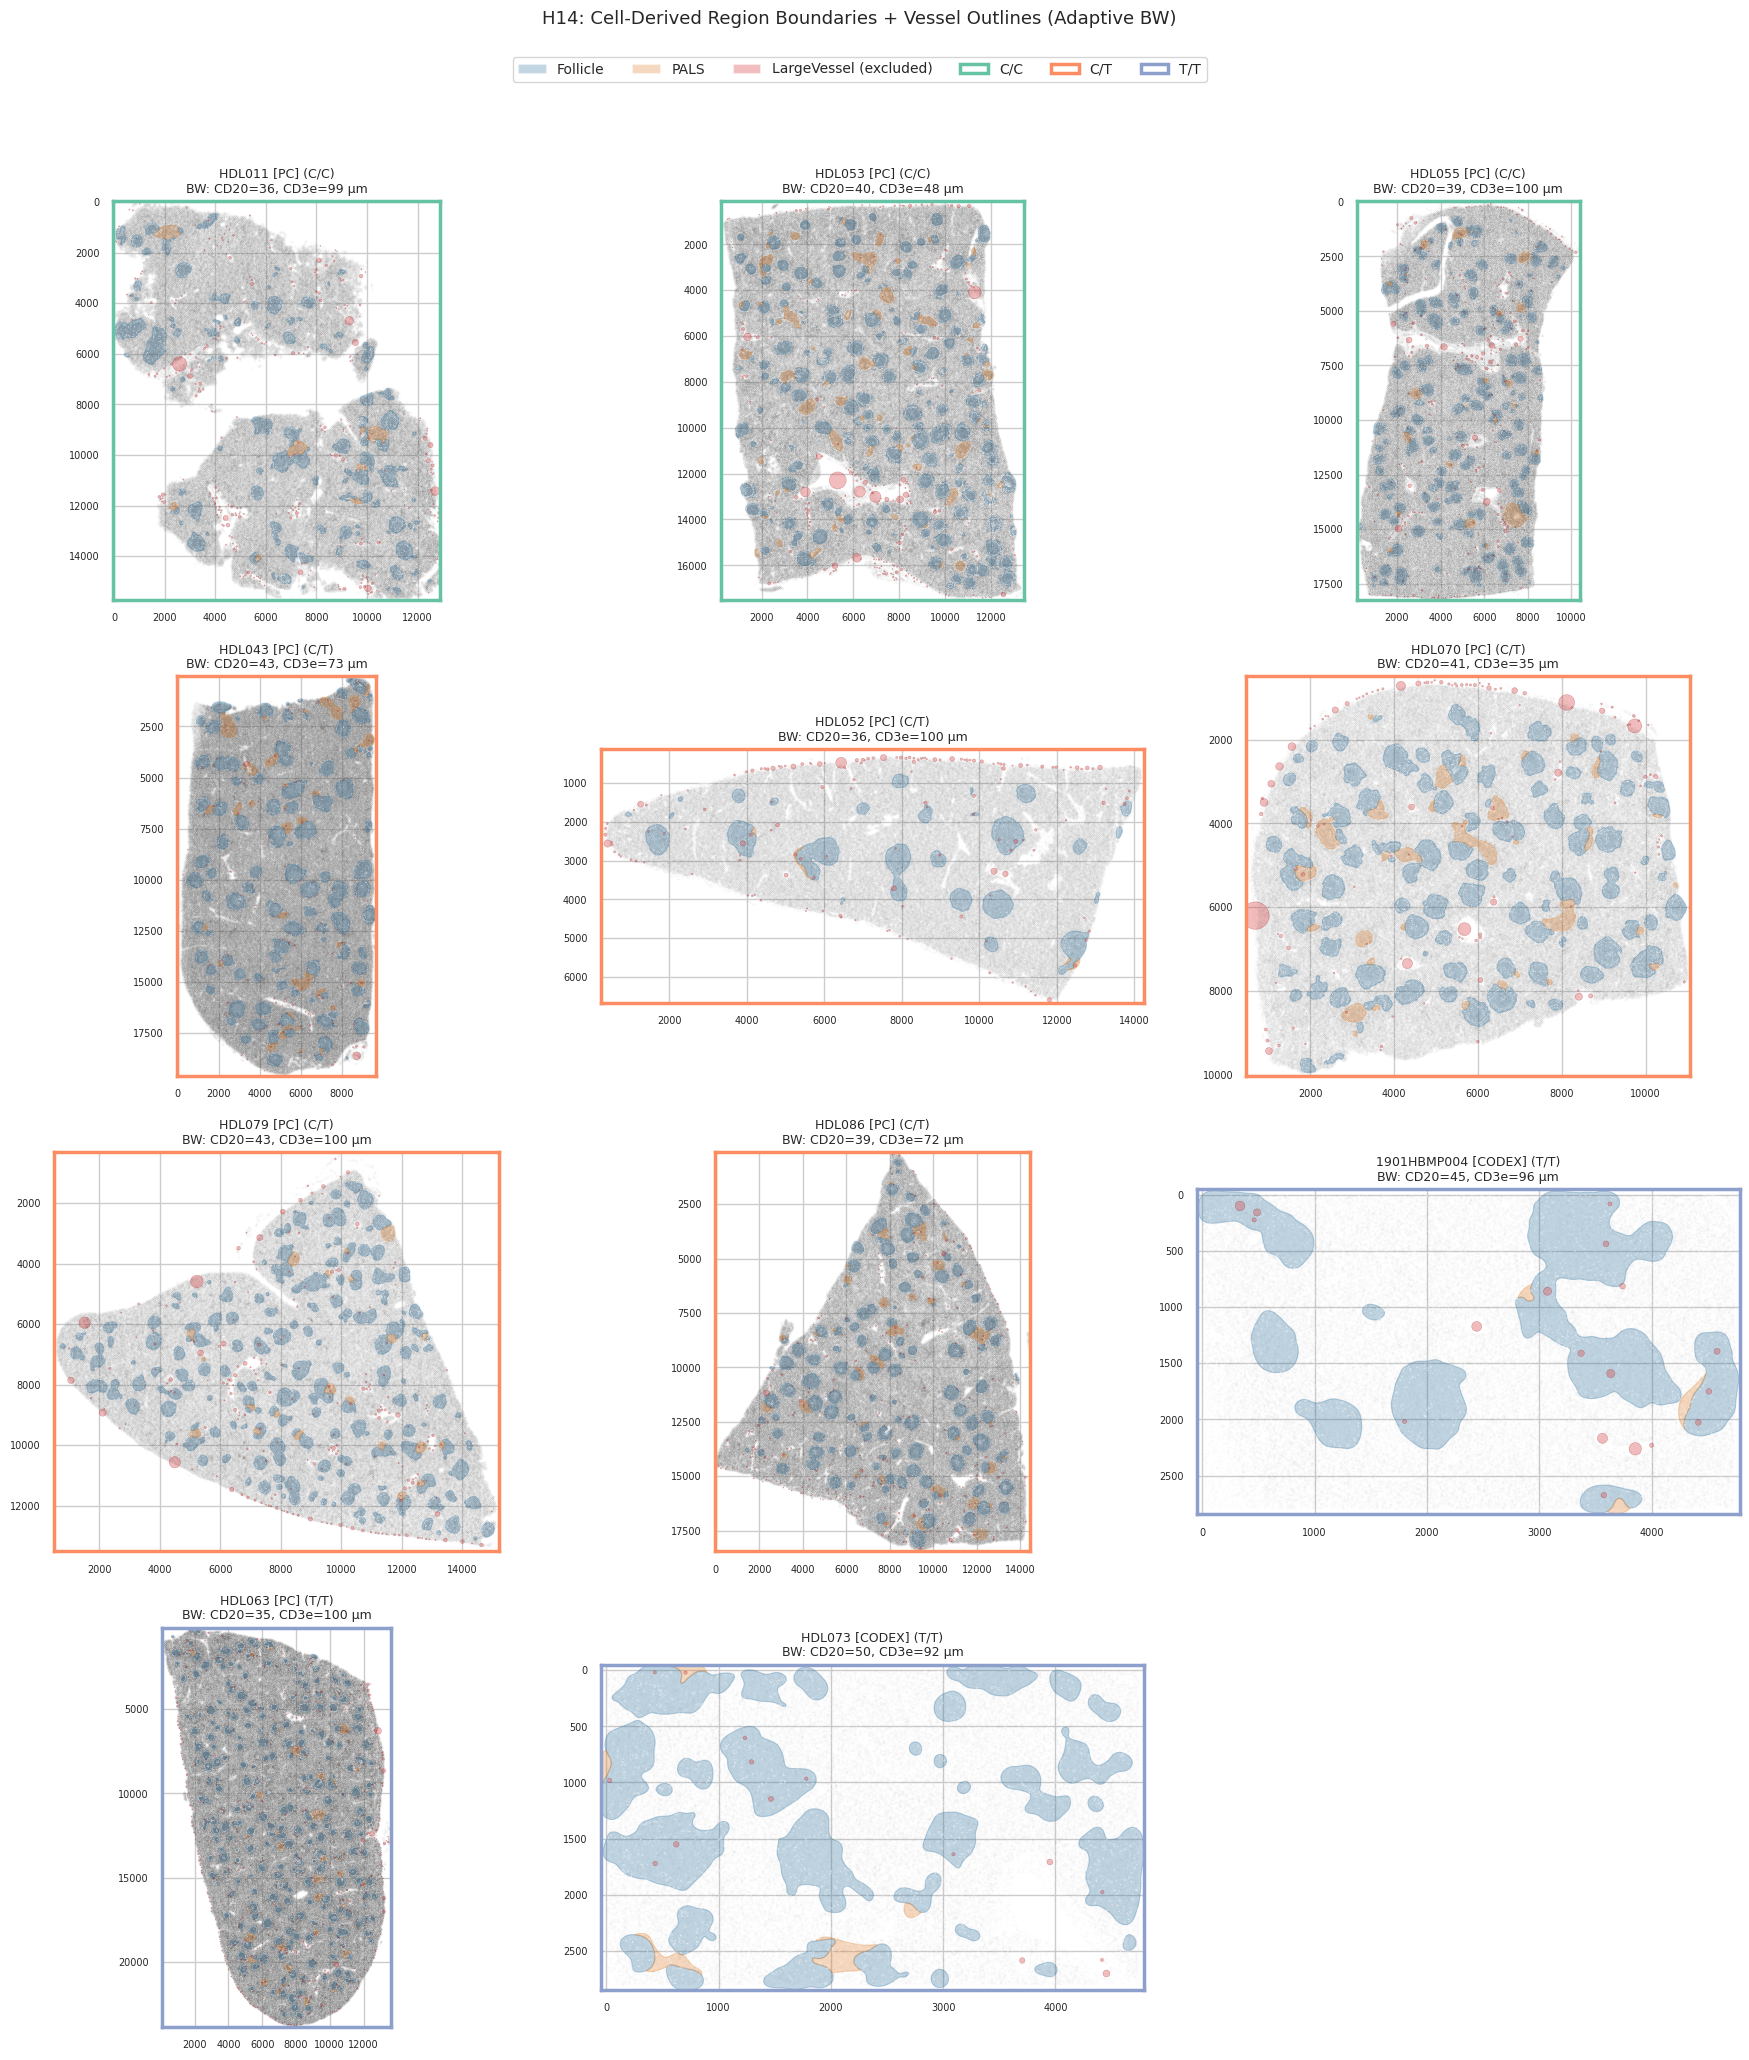

In [8]:
# Visualization: filled regions + vessel outlines + cell context
def shapely_to_mpl(poly, **kwargs):
    ext = np.array(poly.exterior.coords)
    codes = [MplPath.MOVETO] + [MplPath.LINETO] * (len(ext) - 2) + [MplPath.CLOSEPOLY]
    verts = ext.copy()
    for interior in poly.interiors:
        hole = np.array(interior.coords)
        codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(hole) - 2) + [MplPath.CLOSEPOLY]
        verts = np.vstack([verts, hole])
    return PathPatch(MplPath(verts, codes), **kwargs)

def union_to_list(polys):
    """Merge overlapping polygons into non-overlapping set via unary_union."""
    if not polys:
        return []
    u = unary_union(polys)
    if u.geom_type == "MultiPolygon":
        return list(u.geoms)
    elif u.geom_type == "Polygon" and not u.is_empty:
        return [u]
    return []

# Flag threshold — SmallVessels above this are suspect misclassifications
SV_FLAG_THRESHOLD = 1000  # µm²

# Sort images by genotype then sample ID for grouped layout
images_to_plot = sorted(follicle_polys.keys(),
                        key=lambda x: (GENO_ORDER.index(GENOTYPE_MAP.get(img_to_sample[x], "?")),
                                       img_to_sample[x]))
n_imgs = len(images_to_plot)
ncols = min(3, n_imgs)
nrows = int(np.ceil(n_imgs / ncols))
fol_color, pals_color = "#3274A1", "#E1812C"
geno_border = {"C/C": "#66c2a5", "C/T": "#fc8d62", "T/T": "#8da0cb"}

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
axes = np.atleast_2d(axes)
if axes.shape[0] == 1 and nrows > 1:
    axes = axes.T
if axes.shape[1] == 1 and ncols > 1:
    axes = axes.reshape(nrows, ncols)

for idx, image in enumerate(images_to_plot):
    r, c = divmod(idx, ncols)
    ax = axes[r, c]
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    bw = image_bandwidths[image]
    xy = cell_xy[image]
    platform = "CODEX" if sid in CODEX_SAMPLES else "PC"

    # Gray cell dots (subsample for speed)
    ax.scatter(xy[::5, 0], xy[::5, 1], s=0.02, c="gray", alpha=0.1, rasterized=True)

    # Region polygons — merge overlapping before drawing for uniform color
    for polys, color in [(follicle_polys[image], fol_color), (pals_polys[image], pals_color)]:
        for poly in union_to_list(polys):
            ax.add_patch(shapely_to_mpl(poly, facecolor=color, alpha=0.3,
                                         edgecolor=color, linewidth=0.8))

    # SmallVessel circles (white outlines)
    img_v = vessels_crop[vessels_crop["Image"] == image]
    if not img_v.empty:
        vx, vy = img_v[X_COL].values, img_v[Y_COL].values
        vr = np.sqrt(img_v["Area µm^2"].values / np.pi)
        circles = [Circle((x, y), radius) for x, y, radius in zip(vx, vy, vr)]
        pc = PatchCollection(circles, facecolors="none", edgecolors="white",
                             linewidths=0.3, alpha=0.6)
        ax.add_collection(pc)

    # LargeVessel circles (red outlines) — arterioles excluded from fraction
    img_lv = large_vessels_crop[large_vessels_crop["Image"] == image]
    if not img_lv.empty:
        lvx, lvy = img_lv[X_COL].values, img_lv[Y_COL].values
        lvr = np.sqrt(img_lv["Area µm^2"].values / np.pi)
        lv_circles = [Circle((x, y), radius) for x, y, radius in zip(lvx, lvy, lvr)]
        pc_lv = PatchCollection(lv_circles, facecolors="#d62728", edgecolors="darkred",
                                linewidths=0.4, alpha=0.3)
        ax.add_collection(pc_lv)

    ax.set_xlim(xy[:, 0].min() - 50, xy[:, 0].max() + 50)
    ax.set_ylim(xy[:, 1].max() + 50, xy[:, 1].min() - 50)  # y-inverted (image convention)
    ax.set_aspect("equal")
    ax.set_title(f"{sid} [{platform}] ({geno})\nBW: CD20={bw['cd20']:.0f}, CD3e={bw['cd3e']:.0f} \u00b5m",
                 fontsize=9)
    ax.tick_params(labelsize=7)

    # Color border by genotype
    for spine in ax.spines.values():
        spine.set_edgecolor(geno_border.get(geno, "black"))
        spine.set_linewidth(2.5)

for idx in range(n_imgs, nrows * ncols):
    r, c = divmod(idx, ncols)
    axes[r, c].set_visible(False)

# Legend: regions + genotype borders
region_handles = [Patch(facecolor=fol_color, alpha=0.3, label="Follicle"),
                  Patch(facecolor=pals_color, alpha=0.3, label="PALS"),
                  Patch(facecolor="#d62728", alpha=0.3, label="LargeVessel (excluded)")]
geno_handles = [Patch(facecolor="none", edgecolor=geno_border[g], linewidth=2.5, label=g)
                for g in GENO_ORDER]

fig.suptitle("H14: Cell-Derived Region Boundaries + Vessel Outlines (Adaptive BW)",
             fontsize=13, y=1.03)
fig.legend(handles=region_handles + geno_handles,
           loc="upper center", ncol=6, fontsize=10,
           bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=[0, 0, 1, 0.98])
save_figure(fig, "H14_vessel_mask_regions")
plt.show()

Saved: analysis/figures/H14_crop_context.png


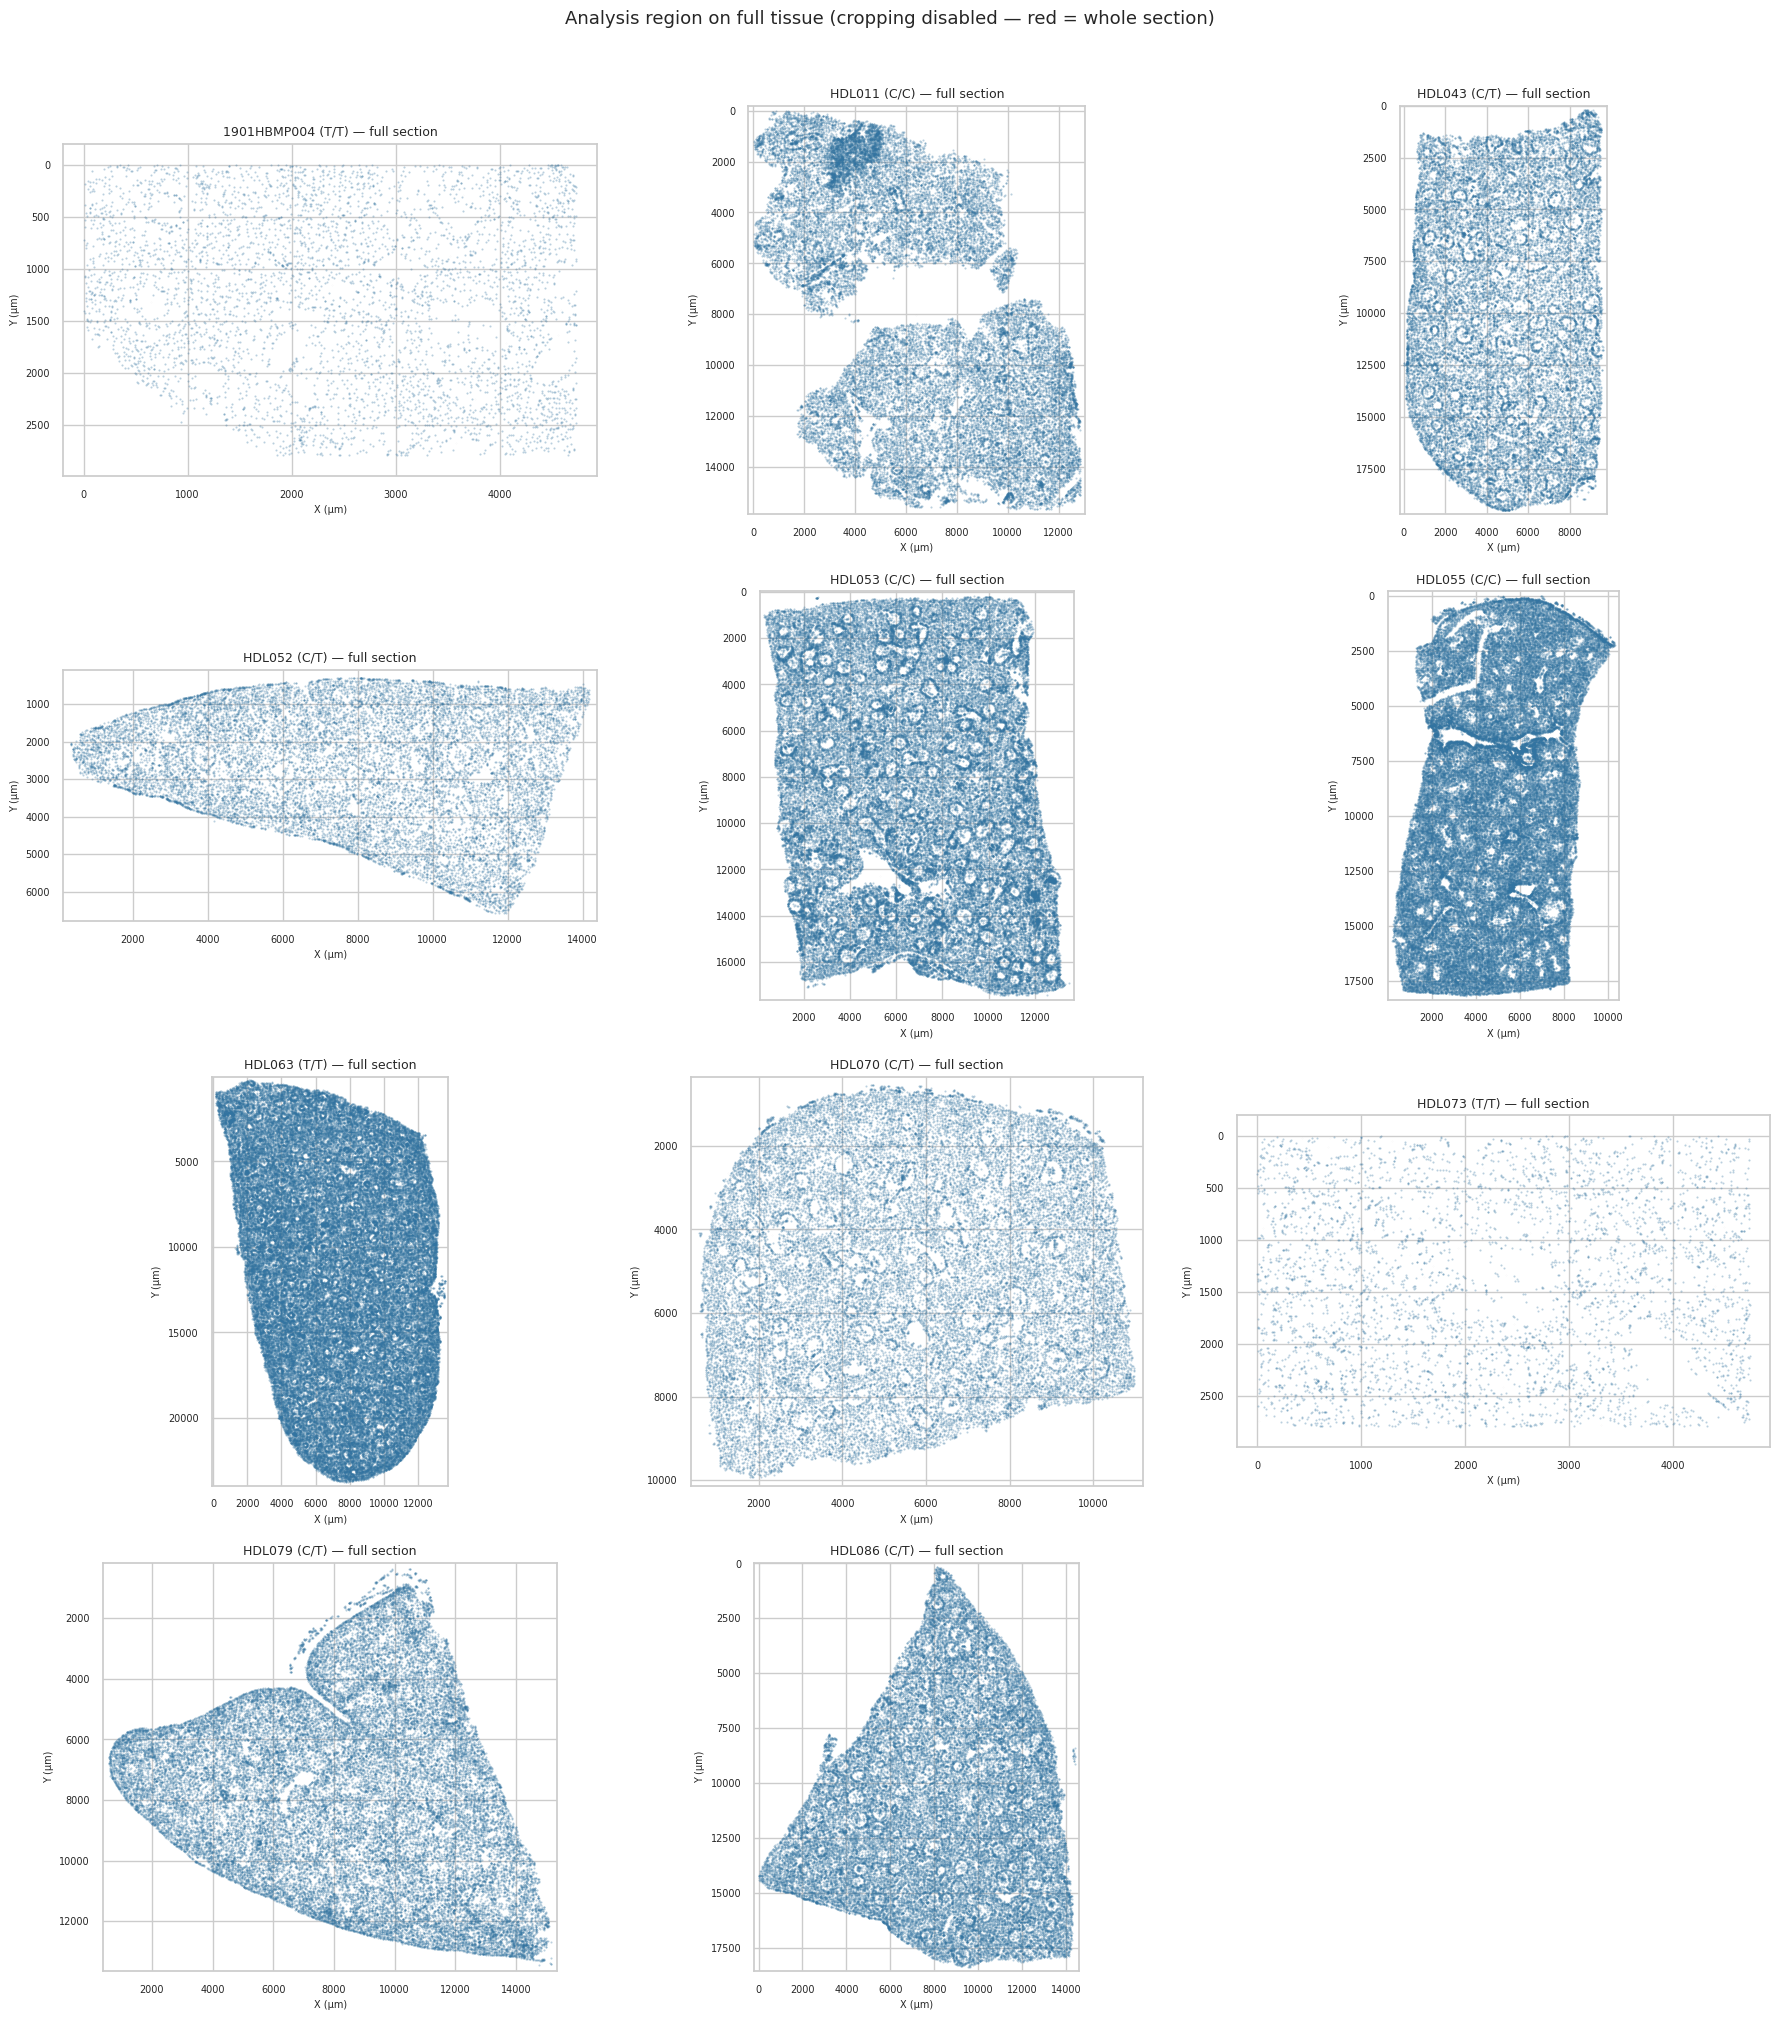

In [9]:
# Full-tissue context: show where the crop window sits on each image
images_to_plot_ctx = sorted(follicle_polys.keys(), key=lambda x: img_to_sample[x])
n_ctx = len(images_to_plot_ctx)
ncols_ctx = min(3, n_ctx)
nrows_ctx = int(np.ceil(n_ctx / ncols_ctx))

fig_ctx, axes_ctx = plt.subplots(nrows_ctx, ncols_ctx, figsize=(6 * ncols_ctx, 5 * nrows_ctx))
axes_ctx = np.atleast_2d(axes_ctx)
if axes_ctx.shape[0] == 1 and nrows_ctx > 1:
    axes_ctx = axes_ctx.T
if axes_ctx.shape[1] == 1 and ncols_ctx > 1:
    axes_ctx = axes_ctx.reshape(nrows_ctx, ncols_ctx)

for idx, image in enumerate(images_to_plot_ctx):
    r, c = divmod(idx, ncols_ctx)
    ax = axes_ctx[r, c]
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")

    # ALL annotations for this image (uncropped)
    img_all = df_all[df_all["Image"] == image]
    ax.scatter(img_all[X_COL].values[::3], img_all[Y_COL].values[::3],
               s=0.01, c="gray", alpha=0.15, rasterized=True)

    # SmallVessel locations (uncropped) in blue
    sv_all = img_all[img_all["Classification"] == "SmallVessel"]
    if not sv_all.empty:
        ax.scatter(sv_all[X_COL].values, sv_all[Y_COL].values,
                   s=0.3, c="#3274A1", alpha=0.3, rasterized=True)

    # Crop window rectangle
    window = crop_windows.get(sid)
    if window is not None:
        cx, cy = window
        ax.add_patch(plt.Rectangle((cx - half_w, cy - half_h), CROP_W, CROP_H,
                                    fill=False, edgecolor="red", linewidth=2.5,
                                    linestyle="-", zorder=10))
        ax.set_title(f"{sid} ({geno}) — crop {CROP_W}×{CROP_H} µm", fontsize=9)
    else:
        ax.set_title(f"{sid} ({geno}) — full section", fontsize=9)

    # Full extent with padding
    x_vals = img_all[X_COL].values
    y_vals = img_all[Y_COL].values
    pad = 200
    ax.set_xlim(x_vals.min() - pad, x_vals.max() + pad)
    ax.set_ylim(y_vals.max() + pad, y_vals.min() - pad)  # y-inverted
    ax.set_aspect("equal")
    ax.tick_params(labelsize=7)
    ax.set_xlabel("X (µm)", fontsize=7)
    ax.set_ylabel("Y (µm)", fontsize=7)

for idx in range(n_ctx, nrows_ctx * ncols_ctx):
    r, c = divmod(idx, ncols_ctx)
    axes_ctx[r, c].set_visible(False)

fig_ctx.suptitle("Analysis region on full tissue (cropping disabled — red = whole section)",
                 fontsize=13, y=1.01)
plt.tight_layout()
save_figure(fig_ctx, "H14_crop_context")
plt.show()

---
### Detailed Vessel Area Verification

Per-image panels showing **filled vessel areas** (proportional circles) overlaid on cell-derived region polygons. Each vessel is drawn at its true area and colored by region assignment:
- **Blue** = SmallVessel inside Follicle polygon
- **Orange** = SmallVessel inside PALS polygon
- **Gray** = SmallVessel unassigned (outside both)
- **Red filled** = LargeVessel (excluded from area fraction denominator)
- **Yellow diamond** = Flagged SmallVessel (area > 1000 µm², likely misclassified LargeVessel)

Dashed red rectangle shows the **crop window** (5000x3000 µm). Y-axis is inverted to match image orientation. Text annotations show effective area after LV exclusion and the vessel area fraction.

Saved: analysis/figures/H14_vessel_area_verification_full.png


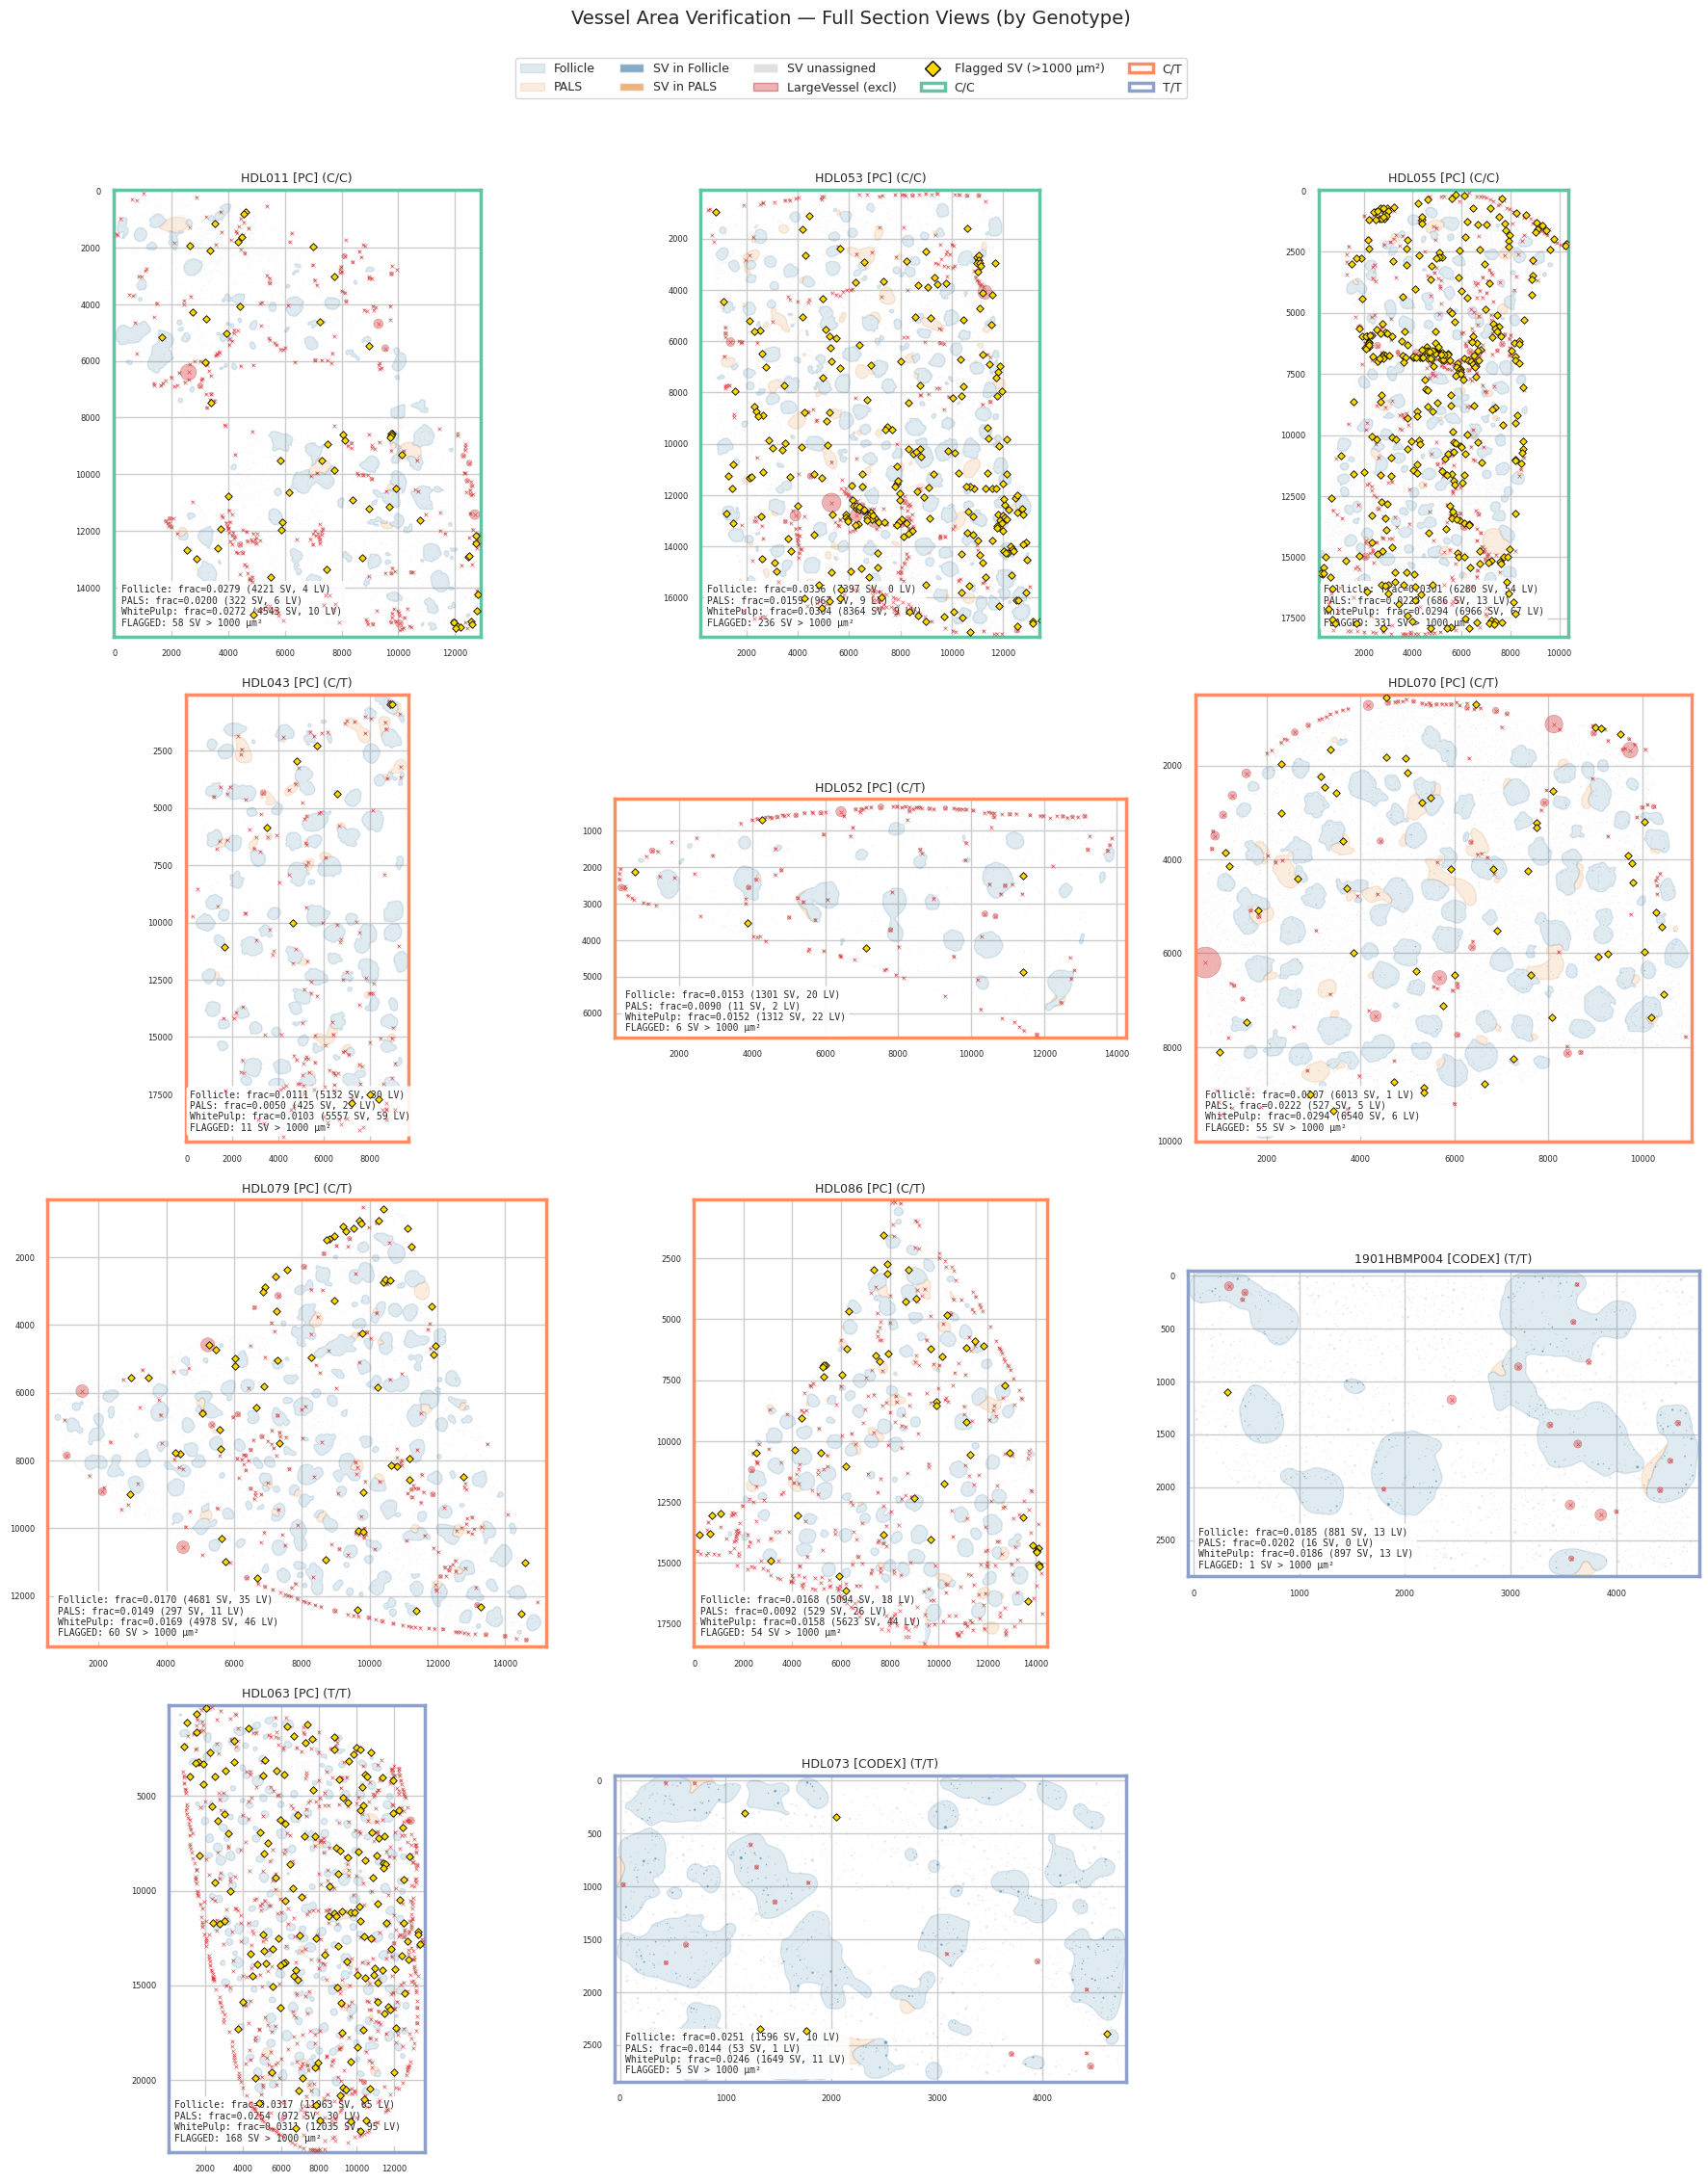

Saved: analysis/figures/H14_vessel_area_verification_zoom.png


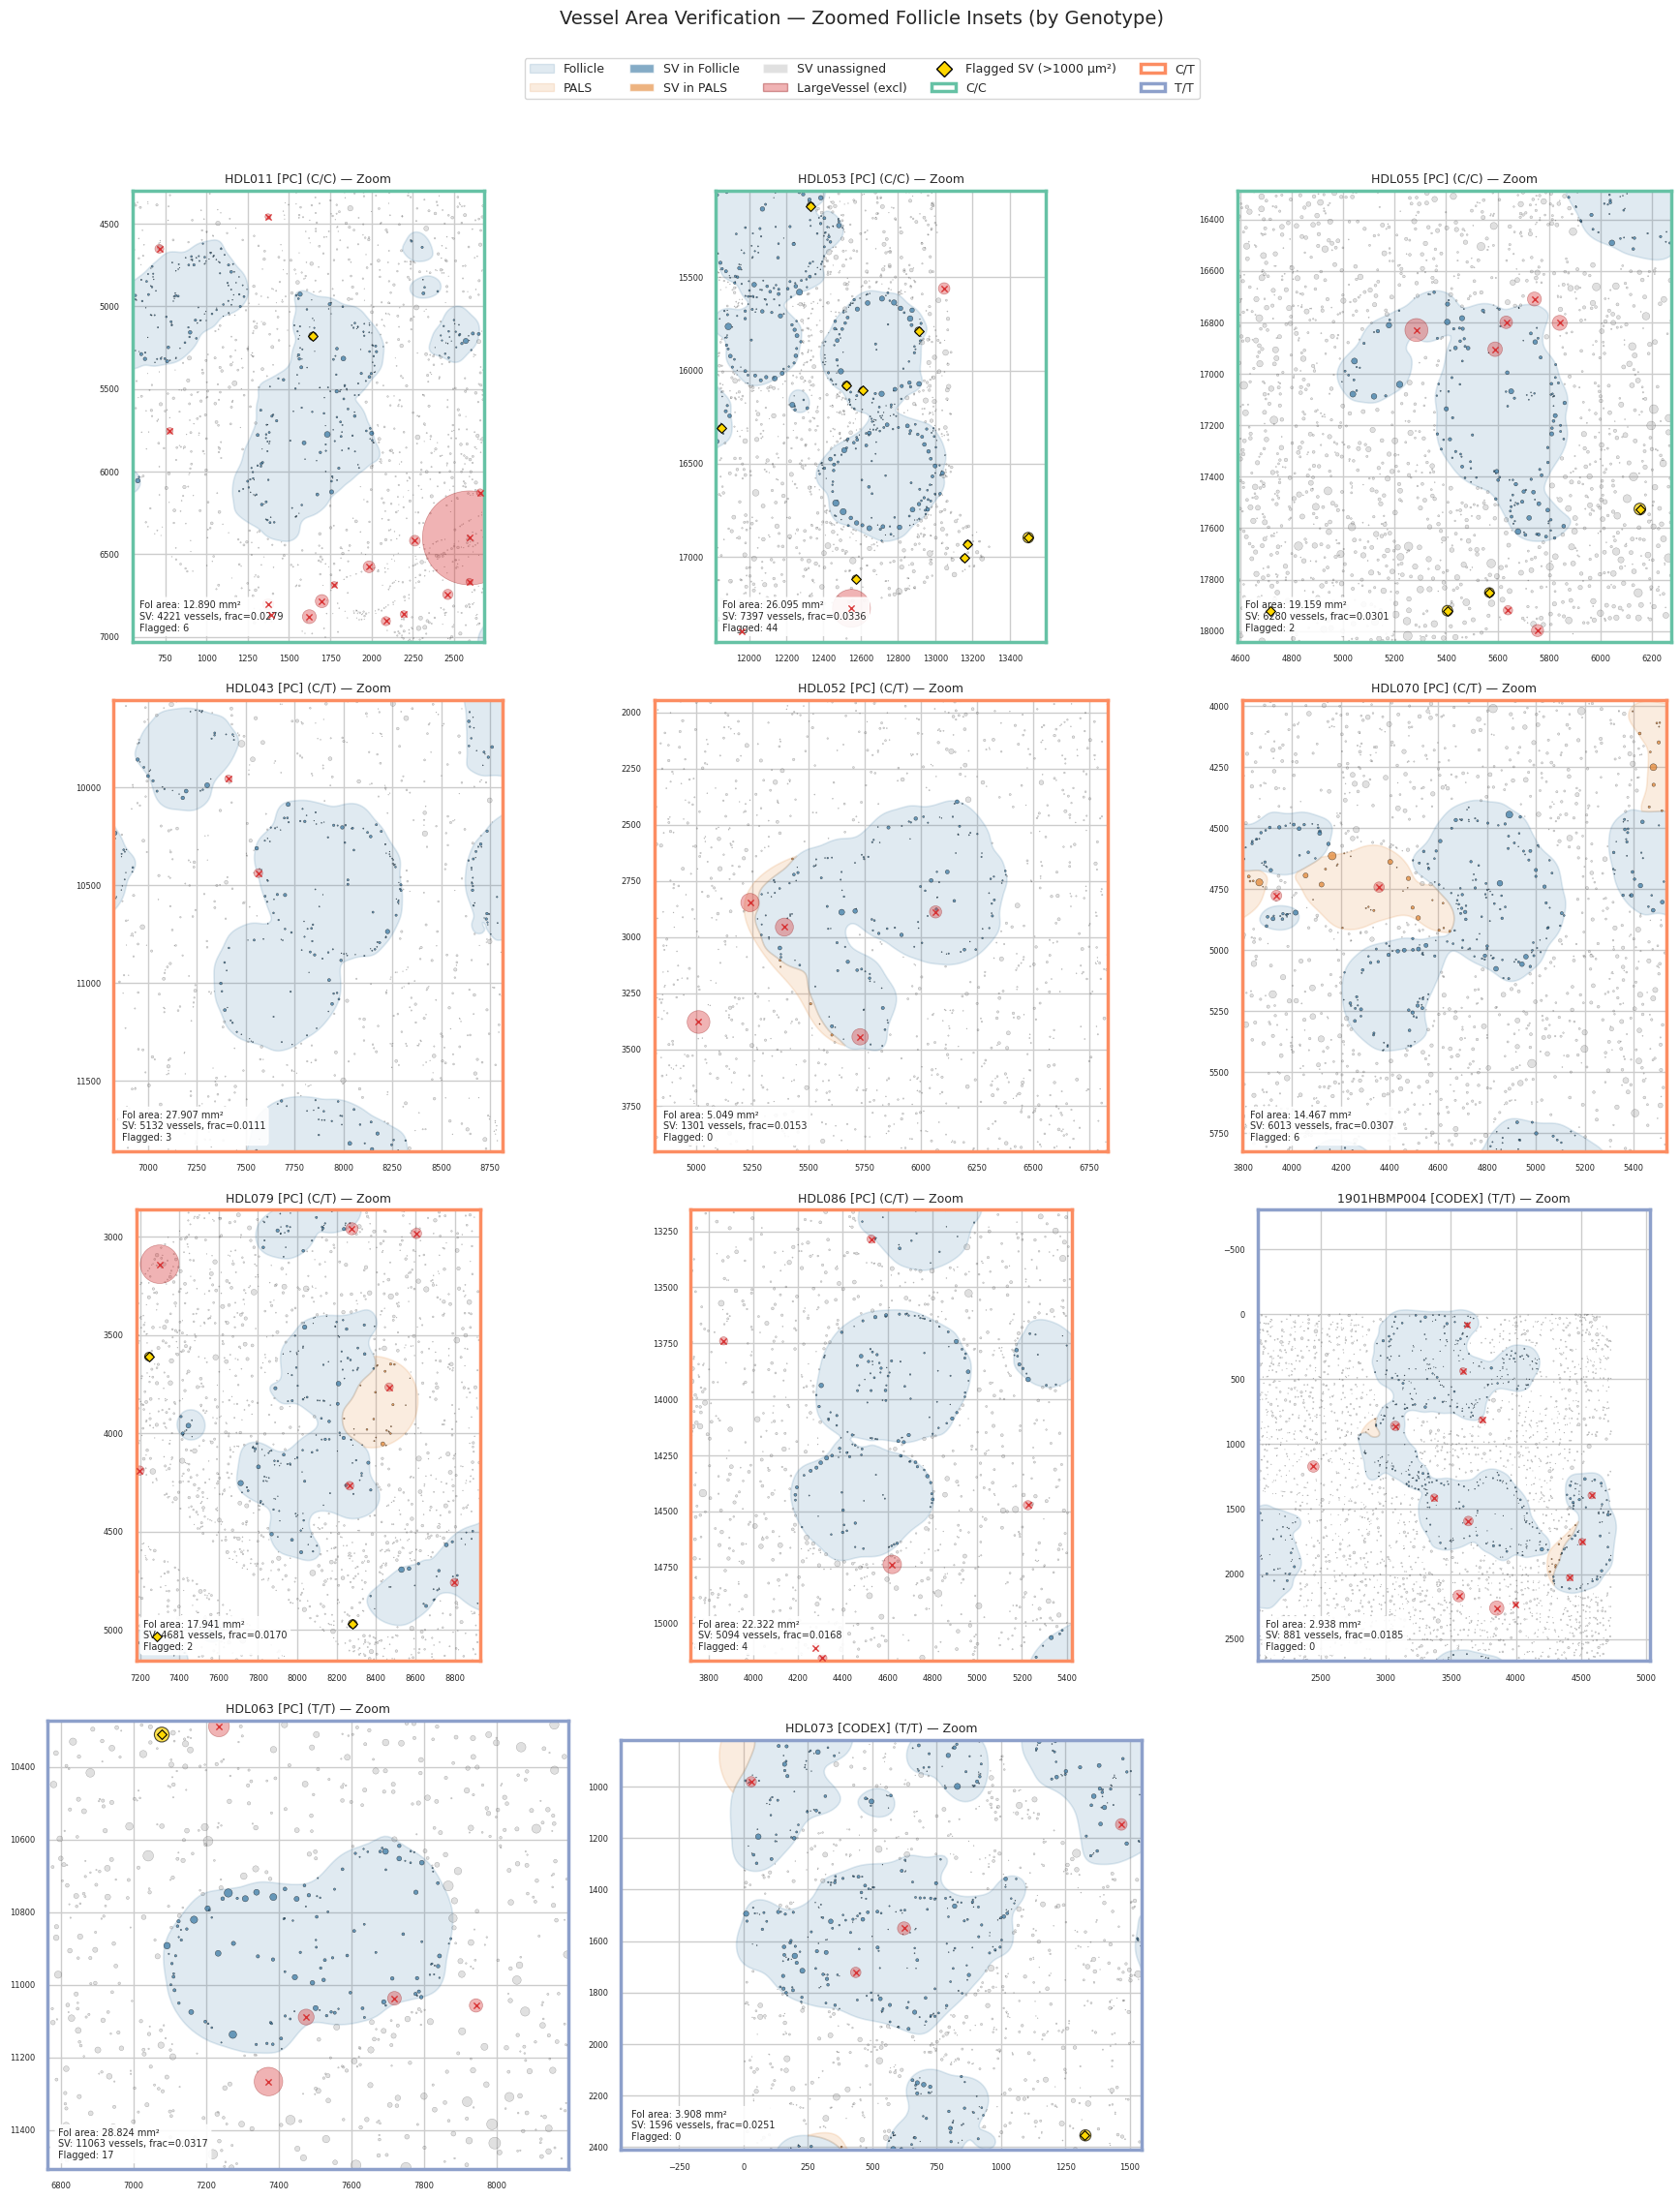


=== Flagged SmallVessels > 1000 µm² ===
Total: 985 across 11 samples
Total flagged area: 1655805 µm² (1.6558 mm²)

Per-sample:
  1901HBMP004     :   1 flagged, area=1023 µm², max=1023 µm²
  HDL011          :  58 flagged, area=137227 µm², max=40652 µm²
  HDL043          :  11 flagged, area=15574 µm², max=2153 µm²
  HDL052          :   6 flagged, area=7422 µm², max=1796 µm²
  HDL053          : 236 flagged, area=399579 µm², max=13542 µm²
  HDL055          : 331 flagged, area=590910 µm², max=16484 µm²
  HDL063          : 168 flagged, area=231948 µm², max=4856 µm²
  HDL070          :  55 flagged, area=75341 µm², max=2582 µm²
  HDL073          :   5 flagged, area=6715 µm², max=1500 µm²
  HDL079          :  60 flagged, area=102573 µm², max=5196 µm²
  HDL086          :  54 flagged, area=87495 µm², max=6099 µm²

Top 20 largest:


,Sample,Genotype,Area_um2,Circularity,Region_Assignment,X_um,Y_um
0,HDL011,C/C,40652.1,0.06,Unassigned,11971.50,15236.2
1,HDL055,C/C,16484.4,0.01,Unassigned,3037.40,6731.2
2,HDL055,C/C,16315.3,0.03,Unassigned,4374.90,1203.1
3,HDL055,C/C,15216.9,0.07,Unassigned,5107.50,6659.2
4,HDL053,C/C,13542.1,0.25,Unassigned,11011.30,3304.3
5,HDL053,C/C,12427.2,0.03,Unassigned,6773.10,12795.5
6,HDL053,C/C,11676.5,0.07,Unassigned,6166.10,12423.0
7,HDL055,C/C,10708.1,0.02,Unassigned,2954.00,5840.6
8,HDL053,C/C,9478.7,0.07,Unassigned,7154.80,13042.8
9,HDL055,C/C,9473.6,0.09,Unassigned,4942.30,6653.1


Saved: analysis/tables/H14_flagged_large_smallvessels.csv


In [10]:
# ---------------------------------------------------------------------------
# Detailed per-image vessel area verification
# Zoomed follicle insets organized by genotype (sorted rows)
# SmallVessels drawn as filled circles, LargeVessels as red circles
# Flagged large SmallVessels (>SV_FLAG_THRESHOLD) shown as yellow diamonds
# ---------------------------------------------------------------------------

VESSEL_REGION_COLORS = {"Follicle": fol_color, "PALS": pals_color, "Unassigned": "#999999"}
LV_COLOR = "#d62728"
FLAG_COLOR = "#FFD700"  # yellow for flagged SmallVessels

# Sort by genotype then sample ID
images_sorted = sorted(follicle_polys.keys(),
                       key=lambda x: (GENO_ORDER.index(GENOTYPE_MAP.get(img_to_sample[x], "?")),
                                      img_to_sample[x]))
n_imgs = len(images_sorted)
geno_border = {"C/C": "#66c2a5", "C/T": "#fc8d62", "T/T": "#8da0cb"}

# Collect flagged vessels for the summary table
all_flagged = []

# --- Full crop views (sorted by genotype) ---
ncols_full = min(3, n_imgs)
nrows_full = int(np.ceil(n_imgs / ncols_full))

fig_full, axes_full = plt.subplots(nrows_full, ncols_full, figsize=(6 * ncols_full, 5.5 * nrows_full))
axes_full = np.atleast_2d(axes_full)
if axes_full.shape[0] == 1 and nrows_full > 1:
    axes_full = axes_full.T

for idx, image in enumerate(images_sorted):
    r, c = divmod(idx, ncols_full)
    ax = axes_full[r, c]
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    platform = "CODEX" if sid in CODEX_SAMPLES else "PC"
    xy = cell_xy[image]

    img_v = vessels_crop[vessels_crop["Image"] == image].copy()
    img_lv = large_vessels_crop[large_vessels_crop["Image"] == image].copy()

    if img_v.empty:
        ax.text(0.5, 0.5, "No vessels", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue

    v_coords = img_v[[X_COL, Y_COL]].values
    v_areas = img_v["Area µm^2"].values
    v_radii = np.sqrt(v_areas / np.pi)

    lv_coords = img_lv[[X_COL, Y_COL]].values if not img_lv.empty else np.empty((0, 2))
    lv_areas = img_lv["Area µm^2"].values if not img_lv.empty else np.array([])
    lv_radii = np.sqrt(lv_areas / np.pi) if len(lv_areas) > 0 else np.array([])

    # Assign SmallVessels to regions
    poly_dict = {}
    if follicle_polys[image]:
        poly_dict["Follicle"] = follicle_polys[image]
    if pals_polys[image]:
        poly_dict["PALS"] = pals_polys[image]
    v_labels = (assign_objects_to_polygons(v_coords, poly_dict)
                if poly_dict else np.full(len(v_coords), "Unassigned", dtype=object))

    # Identify flagged large SmallVessels
    flagged_mask = v_areas > SV_FLAG_THRESHOLD
    n_flagged = flagged_mask.sum()
    if n_flagged > 0:
        for fi in np.where(flagged_mask)[0]:
            all_flagged.append({
                "Sample": sid, "Genotype": geno,
                "Object_ID": img_v.iloc[fi]["Object ID"],
                "Area_um2": v_areas[fi],
                "Circularity": img_v.iloc[fi]["Circularity"],
                "X_um": v_coords[fi, 0], "Y_um": v_coords[fi, 1],
                "Region_Assignment": v_labels[fi],
            })

    img_res = results[results["Image"] == image]
    normal_mask = ~flagged_mask

    # Region polygons
    for polys, color in [(follicle_polys[image], fol_color),
                          (pals_polys[image], pals_color)]:
        for poly in union_to_list(polys):
            ax.add_patch(shapely_to_mpl(poly, facecolor=color, alpha=0.15,
                                         edgecolor=color, linewidth=1.0))

    # SmallVessel circles colored by assignment
    for label, color in VESSEL_REGION_COLORS.items():
        mask = normal_mask & (v_labels == label)
        if not mask.any():
            continue
        circles = [Circle((x, y), r_) for x, y, r_ in
                   zip(v_coords[mask, 0], v_coords[mask, 1], v_radii[mask])]
        alpha = 0.6 if label != "Unassigned" else 0.25
        pc = PatchCollection(circles, facecolors=color, edgecolors="white",
                             linewidths=0.2, alpha=alpha)
        ax.add_collection(pc)

    # Flagged large SmallVessels
    if flagged_mask.any():
        flag_circles = [Circle((x, y), r_) for x, y, r_ in
                        zip(v_coords[flagged_mask, 0], v_coords[flagged_mask, 1],
                            v_radii[flagged_mask])]
        pc_flag = PatchCollection(flag_circles, facecolors=FLAG_COLOR,
                                   edgecolors="black", linewidths=0.6, alpha=0.7)
        ax.add_collection(pc_flag)
        ax.scatter(v_coords[flagged_mask, 0], v_coords[flagged_mask, 1],
                   marker="D", s=15, c=FLAG_COLOR, edgecolors="black",
                   linewidths=0.6, zorder=6)

    # LargeVessel circles
    if len(lv_coords) > 0:
        lv_circles = [Circle((x, y), r_) for x, y, r_ in
                      zip(lv_coords[:, 0], lv_coords[:, 1], lv_radii)]
        pc_lv = PatchCollection(lv_circles, facecolors=LV_COLOR, edgecolors="darkred",
                                linewidths=0.4, alpha=0.35)
        ax.add_collection(pc_lv)
        ax.scatter(lv_coords[:, 0], lv_coords[:, 1], marker="x", s=8,
                   c=LV_COLOR, linewidths=0.5, alpha=0.7, zorder=5)

    # Annotation text
    text_lines = []
    for _, rr in img_res.iterrows():
        reg = rr["Region"]
        frac = rr["Vessel_Area_Fraction"]
        cnt = int(rr["Vessel_Count"])
        lv_n = int(rr["LargeVessel_Count"])
        text_lines.append(f"{reg}: frac={frac:.4f} ({cnt} SV, {lv_n} LV)")
    if n_flagged > 0:
        text_lines.append(f"FLAGGED: {n_flagged} SV > {SV_FLAG_THRESHOLD} \u00b5m\u00b2")
    ax.text(0.02, 0.02, "\n".join(text_lines), transform=ax.transAxes,
            fontsize=7, va="bottom", family="monospace",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.9))

    pad = 50
    ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)
    ax.set_ylim(xy[:, 1].max() + pad, xy[:, 1].min() - pad)
    ax.set_aspect("equal")
    ax.set_title(f"{sid} [{platform}] ({geno})", fontsize=9)
    ax.tick_params(labelsize=6)

    for spine in ax.spines.values():
        spine.set_edgecolor(geno_border.get(geno, "black"))
        spine.set_linewidth(2.5)

for idx in range(n_imgs, nrows_full * ncols_full):
    r, c = divmod(idx, ncols_full)
    axes_full[r, c].set_visible(False)

import matplotlib.lines as mlines
legend_handles = [
    Patch(facecolor=fol_color, alpha=0.15, edgecolor=fol_color, label="Follicle"),
    Patch(facecolor=pals_color, alpha=0.15, edgecolor=pals_color, label="PALS"),
    Patch(facecolor=fol_color, alpha=0.6, label="SV in Follicle"),
    Patch(facecolor=pals_color, alpha=0.6, label="SV in PALS"),
    Patch(facecolor="#999999", alpha=0.3, label="SV unassigned"),
    Patch(facecolor=LV_COLOR, alpha=0.35, edgecolor="darkred", label="LargeVessel (excl)"),
    mlines.Line2D([], [], marker="D", color="w", markerfacecolor=FLAG_COLOR,
                  markeredgecolor="black", markersize=8,
                  label=f"Flagged SV (>{SV_FLAG_THRESHOLD} \u00b5m\u00b2)"),
] + [Patch(facecolor="none", edgecolor=geno_border[g], linewidth=2.5, label=g)
     for g in GENO_ORDER]

fig_full.suptitle("Vessel Area Verification \u2014 Full Section Views (by Genotype)",
                   fontsize=14, y=1.03)
fig_full.legend(handles=legend_handles, loc="upper center", ncol=5, fontsize=9,
                frameon=True, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=[0, 0, 1, 0.98])
save_figure(fig_full, "H14_vessel_area_verification_full")
plt.show()

# --- Zoomed follicle insets (sorted by genotype) ---
fig_zoom, axes_zoom = plt.subplots(nrows_full, ncols_full, figsize=(6 * ncols_full, 5.5 * nrows_full))
axes_zoom = np.atleast_2d(axes_zoom)
if axes_zoom.shape[0] == 1 and nrows_full > 1:
    axes_zoom = axes_zoom.T

for idx, image in enumerate(images_sorted):
    r, c = divmod(idx, ncols_full)
    ax = axes_zoom[r, c]
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    platform = "CODEX" if sid in CODEX_SAMPLES else "PC"

    img_v = vessels_crop[vessels_crop["Image"] == image].copy()
    img_lv = large_vessels_crop[large_vessels_crop["Image"] == image].copy()

    if img_v.empty or not follicle_polys[image]:
        ax.text(0.5, 0.5, f"{sid}\nNo follicle data", ha="center", va="center",
                transform=ax.transAxes)
        ax.set_axis_off()
        continue

    v_coords = img_v[[X_COL, Y_COL]].values
    v_areas = img_v["Area µm^2"].values
    v_radii = np.sqrt(v_areas / np.pi)
    flagged_mask = v_areas > SV_FLAG_THRESHOLD
    normal_mask = ~flagged_mask

    lv_coords = img_lv[[X_COL, Y_COL]].values if not img_lv.empty else np.empty((0, 2))
    lv_areas = img_lv["Area µm^2"].values if not img_lv.empty else np.array([])
    lv_radii = np.sqrt(lv_areas / np.pi) if len(lv_areas) > 0 else np.array([])

    poly_dict = {}
    if follicle_polys[image]:
        poly_dict["Follicle"] = follicle_polys[image]
    if pals_polys[image]:
        poly_dict["PALS"] = pals_polys[image]
    v_labels = (assign_objects_to_polygons(v_coords, poly_dict)
                if poly_dict else np.full(len(v_coords), "Unassigned", dtype=object))

    # Zoom into largest follicle polygon
    biggest = max(follicle_polys[image], key=lambda p: p.area)
    bx = biggest.bounds
    zoom_pad = max((bx[2] - bx[0]), (bx[3] - bx[1])) * 0.4
    zx0, zy0 = bx[0] - zoom_pad, bx[1] - zoom_pad
    zx1, zy1 = bx[2] + zoom_pad, bx[3] + zoom_pad

    # Region polygons
    for polys, color in [(follicle_polys[image], fol_color),
                          (pals_polys[image], pals_color)]:
        for poly in union_to_list(polys):
            ax.add_patch(shapely_to_mpl(poly, facecolor=color, alpha=0.15,
                                         edgecolor=color, linewidth=1.2))

    in_zoom = ((v_coords[:, 0] >= zx0) & (v_coords[:, 0] <= zx1) &
               (v_coords[:, 1] >= zy0) & (v_coords[:, 1] <= zy1))

    # Normal SmallVessels in zoom
    for label, color in VESSEL_REGION_COLORS.items():
        mask = in_zoom & normal_mask & (v_labels == label)
        if not mask.any():
            continue
        circles = [Circle((x, y), r_) for x, y, r_ in
                   zip(v_coords[mask, 0], v_coords[mask, 1], v_radii[mask])]
        alpha = 0.7 if label != "Unassigned" else 0.3
        pc = PatchCollection(circles, facecolors=color, edgecolors="black",
                             linewidths=0.3, alpha=alpha)
        ax.add_collection(pc)

    # Flagged SmallVessels in zoom
    flag_in_zoom = in_zoom & flagged_mask
    if flag_in_zoom.any():
        fc = [Circle((x, y), r_) for x, y, r_ in
              zip(v_coords[flag_in_zoom, 0], v_coords[flag_in_zoom, 1],
                  v_radii[flag_in_zoom])]
        pc_fz = PatchCollection(fc, facecolors=FLAG_COLOR, edgecolors="black",
                                 linewidths=0.8, alpha=0.7)
        ax.add_collection(pc_fz)
        ax.scatter(v_coords[flag_in_zoom, 0], v_coords[flag_in_zoom, 1],
                   marker="D", s=25, c=FLAG_COLOR, edgecolors="black",
                   linewidths=0.8, zorder=6)

    # LargeVessels in zoom
    if len(lv_coords) > 0:
        lv_in_zoom = ((lv_coords[:, 0] >= zx0) & (lv_coords[:, 0] <= zx1) &
                      (lv_coords[:, 1] >= zy0) & (lv_coords[:, 1] <= zy1))
        if lv_in_zoom.any():
            lzc = [Circle((x, y), r_) for x, y, r_ in
                   zip(lv_coords[lv_in_zoom, 0], lv_coords[lv_in_zoom, 1],
                       lv_radii[lv_in_zoom])]
            pc_lz = PatchCollection(lzc, facecolors=LV_COLOR, edgecolors="darkred",
                                     linewidths=0.5, alpha=0.35)
            ax.add_collection(pc_lz)
            ax.scatter(lv_coords[lv_in_zoom, 0], lv_coords[lv_in_zoom, 1],
                       marker="x", s=20, c=LV_COLOR, linewidths=1.0,
                       alpha=0.9, zorder=5)

    # Stats annotation
    all_fol_area = sum(p.area for p in follicle_polys[image])
    fol_sv = v_areas[v_labels == "Follicle"].sum()
    if len(lv_coords) > 0 and poly_dict:
        lv_lab = assign_objects_to_polygons(lv_coords, {"Follicle": follicle_polys[image]})
        lv_in_fol = lv_areas[lv_lab == "Follicle"].sum()
    else:
        lv_in_fol = 0
    eff_fol_area = all_fol_area - lv_in_fol
    zoom_frac = fol_sv / eff_fol_area if eff_fol_area > 0 else 0
    n_sv_fol = int((v_labels == "Follicle").sum())
    n_flag_fol = int((flagged_mask & (v_labels == "Follicle")).sum())
    ax.text(0.02, 0.02,
            f"Fol area: {all_fol_area/1e6:.3f} mm\u00b2\n"
            f"SV: {n_sv_fol} vessels, frac={zoom_frac:.4f}\n"
            f"Flagged: {n_flag_fol}",
            transform=ax.transAxes, fontsize=7, va="bottom",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.9))

    ax.set_xlim(zx0, zx1)
    ax.set_ylim(zy1, zy0)  # y-inverted
    ax.set_aspect("equal")
    ax.set_title(f"{sid} [{platform}] ({geno}) \u2014 Zoom", fontsize=9)
    ax.tick_params(labelsize=6)

    for spine in ax.spines.values():
        spine.set_edgecolor(geno_border.get(geno, "black"))
        spine.set_linewidth(2.5)

for idx in range(n_imgs, nrows_full * ncols_full):
    r, c = divmod(idx, ncols_full)
    axes_zoom[r, c].set_visible(False)

fig_zoom.suptitle("Vessel Area Verification \u2014 Zoomed Follicle Insets (by Genotype)",
                   fontsize=14, y=1.03)
fig_zoom.legend(handles=legend_handles, loc="upper center", ncol=5, fontsize=9,
                frameon=True, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=[0, 0, 1, 0.98])
save_figure(fig_zoom, "H14_vessel_area_verification_zoom")
plt.show()

# --- Flagged vessel summary ---
flagged_df = pd.DataFrame(all_flagged)
if not flagged_df.empty:
    flagged_df = flagged_df.sort_values("Area_um2", ascending=False).reset_index(drop=True)
    print(f"\n=== Flagged SmallVessels > {SV_FLAG_THRESHOLD} \u00b5m\u00b2 ===")
    print(f"Total: {len(flagged_df)} across {flagged_df['Sample'].nunique()} samples")
    print(f"Total flagged area: {flagged_df['Area_um2'].sum():.0f} \u00b5m\u00b2 "
          f"({flagged_df['Area_um2'].sum()/1e6:.4f} mm\u00b2)")
    print(f"\nPer-sample:")
    for sid in sorted(flagged_df["Sample"].unique()):
        sf = flagged_df[flagged_df["Sample"] == sid]
        print(f"  {sid:16s}: {len(sf):3d} flagged, "
              f"area={sf['Area_um2'].sum():.0f} \u00b5m\u00b2, "
              f"max={sf['Area_um2'].max():.0f} \u00b5m\u00b2")
    print(f"\nTop 20 largest:")
    display(flagged_df.head(20)[["Sample", "Genotype", "Area_um2", "Circularity",
                                  "Region_Assignment", "X_um", "Y_um"]].round(2))
    save_table(flagged_df, "H14_flagged_large_smallvessels")
else:
    print("No flagged SmallVessels.")

In [11]:
# ---------------------------------------------------------------------------
# Verification table: recompute vessel area fraction from scratch per image
# Uses all follicle area (combined) minus LargeVessel area as denominator
# Cross-checks against the results table computed above
# ---------------------------------------------------------------------------
xcheck_rows = []

for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")

    img_v = vessels_crop[vessels_crop["Image"] == image]
    img_lv = large_vessels_crop[large_vessels_crop["Image"] == image]
    if img_v.empty:
        continue

    v_coords = img_v[[X_COL, Y_COL]].values
    v_areas = img_v["Area µm^2"].values

    for region_name, r_polys in [("Follicle", follicle_polys[image]),
                                  ("PALS", pals_polys[image]),
                                  ("WhitePulp", wp_polys[image])]:
        region_area = sum(p.area for p in r_polys) if r_polys else 0
        if region_area == 0:
            continue

        # SmallVessel area inside this region
        sv_labels = assign_objects_to_polygons(v_coords, {region_name: r_polys})
        sv_inside = sv_labels == region_name
        sv_area = float(v_areas[sv_inside].sum())
        sv_count = int(sv_inside.sum())

        # LargeVessel area inside this region
        lv_excl = 0.0
        lv_count = 0
        if not img_lv.empty:
            lv_coords = img_lv[[X_COL, Y_COL]].values
            lv_areas_arr = img_lv["Area µm^2"].values
            lv_labels = assign_objects_to_polygons(lv_coords, {region_name: r_polys})
            lv_mask = lv_labels == region_name
            lv_excl = float(lv_areas_arr[lv_mask].sum())
            lv_count = int(lv_mask.sum())

        effective_area = region_area - lv_excl
        recomputed_frac = sv_area / effective_area if effective_area > 0 else 0

        # Original from results table
        orig_row = results[(results["Sample"] == sid) & (results["Region"] == region_name)]
        orig_frac = orig_row["Vessel_Area_Fraction"].values[0] if len(orig_row) else np.nan

        xcheck_rows.append({
            "Sample": sid, "Genotype": geno, "Region": region_name,
            "Region_Area_mm2": region_area / 1e6,
            "LV_Excl_mm2": lv_excl / 1e6,
            "Effective_mm2": effective_area / 1e6,
            "SV_Count": sv_count,
            "SV_Area_mm2": sv_area / 1e6,
            "Original_Frac": orig_frac,
            "Recomputed_Frac": recomputed_frac,
            "Abs_Diff": abs(orig_frac - recomputed_frac) if not np.isnan(orig_frac) else np.nan,
        })

xcheck_df = pd.DataFrame(xcheck_rows)

print("=== Cross-Check: Original vs Recomputed Vessel Area Fraction ===")
print("(Abs_Diff should be ~0 if computation is consistent)\n")

for region in ["Follicle", "PALS", "WhitePulp"]:
    rd = xcheck_df[xcheck_df["Region"] == region]
    max_diff = rd["Abs_Diff"].max()
    print(f"  {region}: max Abs_Diff = {max_diff:.2e}")

print()
display(xcheck_df[xcheck_df["Region"] == "Follicle"][
    ["Sample", "Genotype", "Region_Area_mm2", "LV_Excl_mm2", "Effective_mm2",
     "SV_Count", "Original_Frac", "Recomputed_Frac", "Abs_Diff"]].round(6))

save_table(xcheck_df, "H14_vessel_fraction_crosscheck")

=== Cross-Check: Original vs Recomputed Vessel Area Fraction ===
(Abs_Diff should be ~0 if computation is consistent)

  Follicle: max Abs_Diff = 0.00e+00
  PALS: max Abs_Diff = 0.00e+00
  WhitePulp: max Abs_Diff = 0.00e+00



,Sample,Genotype,Region_Area_mm2,LV_Excl_mm2,Effective_mm2,SV_Count,Original_Frac,Recomputed_Frac,Abs_Diff
0,1901HBMP004,T/T,2.937797,0.034170,2.903627,881,0.018538,0.018538,0.0
3,HDL011,C/C,12.890463,0.006419,12.884044,4221,0.027894,0.027894,0.0
6,HDL043,C/T,27.907215,0.078495,27.828720,5132,0.011072,0.011072,0.0
9,HDL052,C/T,5.049131,0.084221,4.964911,1301,0.015258,0.015258,0.0
12,HDL053,C/C,26.094680,0.000000,26.094680,7397,0.033598,0.033598,0.0
15,HDL055,C/C,19.159263,0.117305,19.041957,6280,0.030058,0.030058,0.0
18,HDL063,T/T,28.823516,0.158541,28.664975,11063,0.031713,0.031713,0.0
21,HDL070,C/T,14.467176,0.001188,14.465988,6013,0.030701,0.030701,0.0
24,HDL073,T/T,3.907712,0.011253,3.896459,1596,0.025100,0.025100,0.0
27,HDL079,C/T,17.940839,0.072654,17.868185,4681,0.016961,0.016961,0.0


Saved: analysis/tables/H14_vessel_fraction_crosscheck.csv


Saved: analysis/figures/H14_boundary_comparison.png


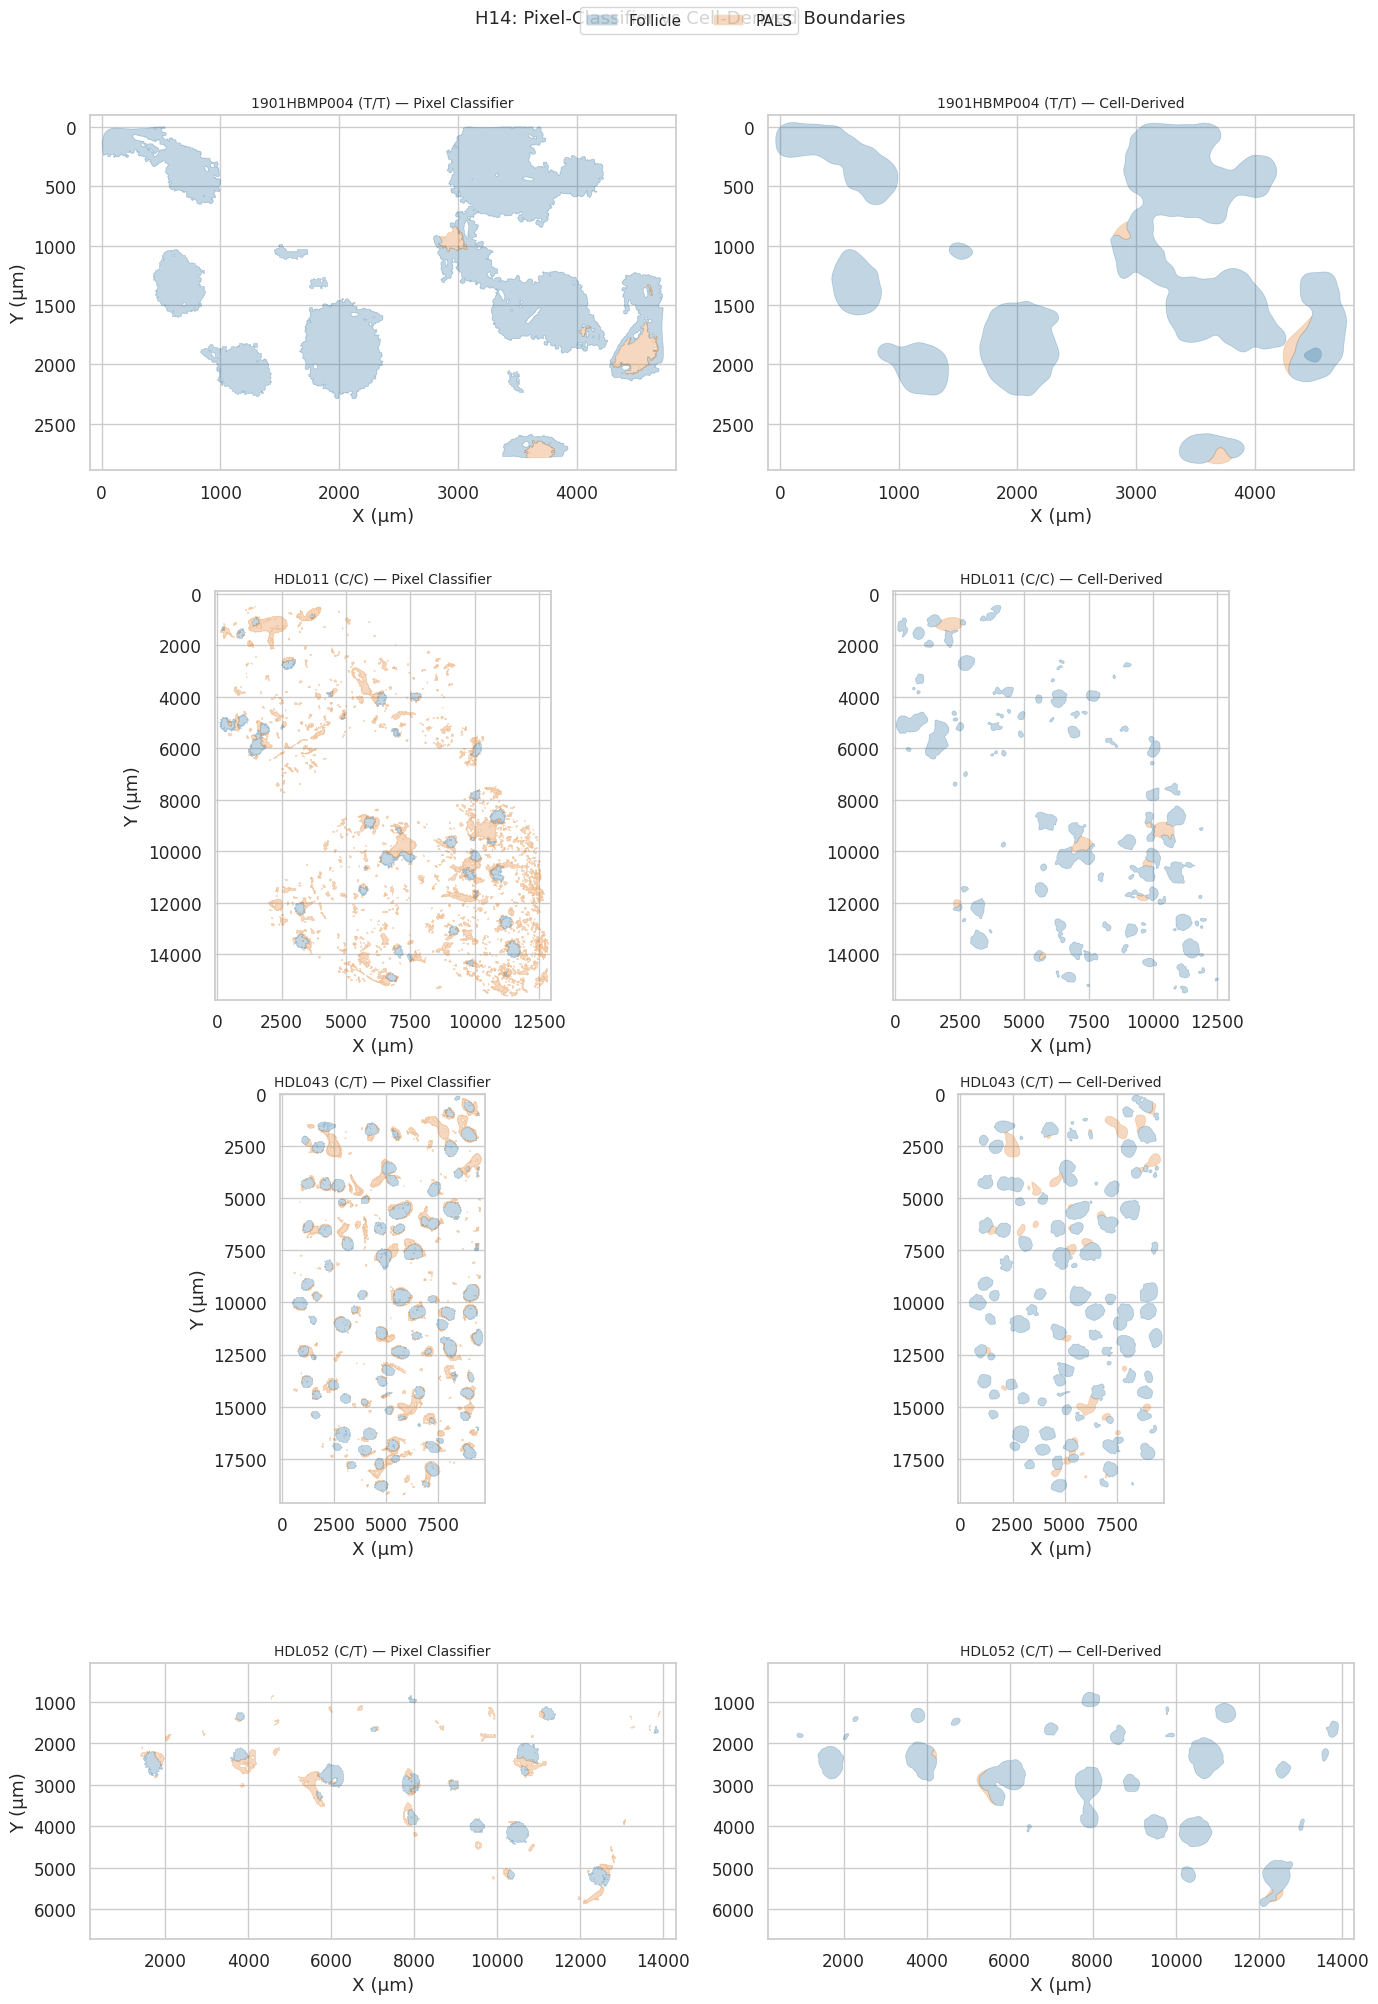

IoU: Cell-derived vs Pixel-classifier:

     Sample Genotype  Follicle_IoU  PALS_IoU
1901HBMP004      T/T         0.803     0.060
     HDL011      C/C         0.318     0.110
     HDL043      C/T         0.648     0.353
     HDL052      C/T         0.290     0.012
     HDL053      C/C         0.683     0.198
     HDL055      C/C         0.419     0.328
     HDL063      T/T         0.523     0.200
     HDL070      C/T         0.571     0.253
     HDL073      T/T         0.434     0.036
     HDL079      C/T         0.441     0.216
     HDL086      C/T         0.669     0.257

Mean Follicle IoU: 0.527
Mean PALS IoU:    0.184
Saved: analysis/tables/H14_iou_comparison.csv


In [12]:
# Pixel-classifier vs cell-derived boundary comparison.
# The pixel-classifier side is the region layer: the same QuPath geometry, but
# scaled to µm once, per donor, by data_utils.get_pixel_size.
_h14_layer = load_region_layer()
_h14_by_sample = {extract_sample_id(stem): polys
                  for stem, polys in _h14_layer.items()}

geojson_map = {image: _h14_by_sample[img_to_sample[image]]
               for image in follicle_polys
               if img_to_sample[image] in _h14_by_sample}

# Pick 4 representative images for side-by-side figure
repr_images = [img for img in sorted(follicle_polys.keys(), key=lambda x: img_to_sample[x])
               if img in geojson_map][:4]

fig, axes = plt.subplots(len(repr_images), 2, figsize=(14, 5 * len(repr_images)))
if len(repr_images) == 1:
    axes = axes[np.newaxis, :]

for row, image in enumerate(repr_images):
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    annots = geojson_map[image]
    xy = cell_xy[image]
    pad = 100

    window = crop_windows.get(sid)
    crop_box = None
    if window is not None:
        cx, cy = window
        crop_box = Polygon([(cx-half_w, cy-half_h), (cx+half_w, cy-half_h),
                             (cx+half_w, cy+half_h), (cx-half_w, cy+half_h)])

    # Left: pixel-classifier
    ax_l = axes[row, 0]
    for cls, color in [("Follicle", fol_color), ("PALS", pals_color)]:
        for poly in annots.get(cls, []):
            if poly.is_empty:
                continue
            p_um = poly
            if crop_box:
                p_um = p_um.intersection(crop_box)
            if p_um.is_empty:
                continue
            draw = list(p_um.geoms) if p_um.geom_type == "MultiPolygon" else [p_um]
            for d in draw:
                if d.geom_type == "Polygon":
                    ax_l.add_patch(shapely_to_mpl(d, facecolor=color, alpha=0.3,
                                                   edgecolor=color, linewidth=0.5))
    ax_l.set_title(f"{sid} ({geno}) — Pixel Classifier", fontsize=10)

    # Right: cell-derived
    ax_r = axes[row, 1]
    for polys, color in [(follicle_polys[image], fol_color), (pals_polys[image], pals_color)]:
        for poly in polys:
            ax_r.add_patch(shapely_to_mpl(poly, facecolor=color, alpha=0.3,
                                           edgecolor=color, linewidth=0.5))
    ax_r.set_title(f"{sid} ({geno}) — Cell-Derived", fontsize=10)

    for ax in [ax_l, ax_r]:
        ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)
        ax.set_ylim(xy[:, 1].max() + pad, xy[:, 1].min() - pad)
        ax.set_aspect("equal"); ax.set_xlabel("X (µm)")
    ax_l.set_ylabel("Y (µm)")

fig.legend(handles=[Patch(facecolor=fol_color, alpha=0.3, label="Follicle"),
                     Patch(facecolor=pals_color, alpha=0.3, label="PALS")],
           loc="upper center", ncol=2, fontsize=11)
fig.suptitle("H14: Pixel-Classifier vs Cell-Derived Boundaries", fontsize=13, y=1.01)
plt.tight_layout()
save_figure(fig, "H14_boundary_comparison")
plt.show()

# Compute IoU for ALL images
iou_rows = []
for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    if image not in geojson_map:
        iou_rows.append({"Sample": sid, "Genotype": geno,
                          "Follicle_IoU": np.nan, "PALS_IoU": np.nan})
        continue
    annots = geojson_map[image]
    window = crop_windows.get(sid)
    crop_box = None
    if window is not None:
        cx, cy = window
        crop_box = Polygon([(cx-half_w, cy-half_h), (cx+half_w, cy-half_h),
                             (cx+half_w, cy+half_h), (cx-half_w, cy+half_h)])
    row_data = {"Sample": sid, "Genotype": geno}
    for cls, cell_polys, key in [("Follicle", follicle_polys[image], "Follicle_IoU"),
                                   ("PALS", pals_polys[image], "PALS_IoU")]:
        pc_polys = annots.get(cls, [])
        if not pc_polys or not cell_polys:
            row_data[key] = np.nan
            continue
        pc_um = []
        for p in pc_polys:
            if p.is_empty:
                continue
            p_um = p
            if not p_um.is_valid:
                p_um = make_valid(p_um)
            if crop_box:
                p_um = p_um.intersection(crop_box)
            if not p_um.is_empty:
                pc_um.append(p_um)
        if not pc_um:
            row_data[key] = np.nan
            continue
        inter = unary_union(pc_um).intersection(unary_union(cell_polys)).area
        union = unary_union(pc_um).union(unary_union(cell_polys)).area
        row_data[key] = inter / union if union > 0 else 0
    iou_rows.append(row_data)

iou_df = pd.DataFrame(iou_rows)
print("IoU: Cell-derived vs Pixel-classifier:\n")
print(iou_df.to_string(index=False, float_format="%.3f"))
print(f"\nMean Follicle IoU: {iou_df['Follicle_IoU'].mean():.3f}")
print(f"Mean PALS IoU:    {iou_df['PALS_IoU'].mean():.3f}")
save_table(iou_df, "H14_iou_comparison")

In [13]:
# Marker enrichment validation
enrichment_rows = []
for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    geno = GENOTYPE_MAP.get(sid, "?")
    poly_dict = {}
    if follicle_polys[image]:
        poly_dict["Follicle"] = follicle_polys[image]
    if pals_polys[image]:
        poly_dict["PALS"] = pals_polys[image]

    row = {"Sample": sid, "Genotype": geno}
    cd20_xy = cd20_coords.get(image)
    cd3e_xy = cd3e_coords.get(image)

    if cd20_xy is not None and len(cd20_xy) > 0 and poly_dict:
        lab20 = assign_objects_to_polygons(cd20_xy, poly_dict)
        row["CD20_in_Follicle"] = (lab20 == "Follicle").mean()
        row["CD20_in_PALS"] = (lab20 == "PALS").mean()
    else:
        row["CD20_in_Follicle"] = row["CD20_in_PALS"] = np.nan

    if cd3e_xy is not None and len(cd3e_xy) > 0 and poly_dict:
        lab3e = assign_objects_to_polygons(cd3e_xy, poly_dict)
        row["CD3e_in_PALS"] = (lab3e == "PALS").mean()
        row["CD3e_in_Follicle"] = (lab3e == "Follicle").mean()
    else:
        row["CD3e_in_PALS"] = row["CD3e_in_Follicle"] = np.nan

    row["n_CD20_high"] = len(cd20_xy) if cd20_xy is not None else 0
    row["n_CD3e_high"] = len(cd3e_xy) if cd3e_xy is not None else 0
    enrichment_rows.append(row)

enrich_df = pd.DataFrame(enrichment_rows)
print("Marker enrichment validation:\n")
print(enrich_df.to_string(index=False, float_format="%.3f"))
print(f"\nMean CD20+ in Follicle: {enrich_df['CD20_in_Follicle'].mean():.3f} (target >0.50)")
print(f"Mean CD3e+ in PALS:    {enrich_df['CD3e_in_PALS'].mean():.3f} (target >0.30)")
print(f"Cross-contamination: CD20 in PALS={enrich_df['CD20_in_PALS'].mean():.3f}, "
      f"CD3e in Follicle={enrich_df['CD3e_in_Follicle'].mean():.3f}")
save_table(enrich_df, "H14_marker_enrichment")

Marker enrichment validation:

     Sample Genotype  CD20_in_Follicle  CD20_in_PALS  CD3e_in_PALS  CD3e_in_Follicle  n_CD20_high  n_CD3e_high
1901HBMP004      T/T             0.896         0.001         0.024             0.571        28654        14410
     HDL011      C/C             0.872         0.004         0.200             0.230       180161        89733
     HDL043      C/T             0.913         0.003         0.362             0.197       292840       146463
     HDL052      C/T             0.816         0.001         0.005             0.248        93806        47380
     HDL053      C/C             0.909         0.001         0.534             0.161       289783       145351
     HDL055      C/C             0.947         0.005         0.209             0.206       210496       105874
     HDL063      T/T             0.949         0.002         0.171             0.281       378805       185300
     HDL070      C/T             0.886         0.002         0.628             0.

---
### Donor Demographics

Summary of the 11 donors in this analysis, grouped by rs3184504 genotype.

=== Donor Characteristics (n=11) ===



,Sample,Genotype,Platform,Age (yrs),Gender,Ethnicity,BMI
0,HDL011,C/C,Phenocycler,8.0,Female,African American,12.0
1,HDL053,C/C,Phenocycler,2.51,Male,Caucasian,20.0
2,HDL055,C/C,Phenocycler,0.26,Male,Caucasian,16.9
3,HDL043,C/T,Phenocycler,2.88,Male,Caucasian,15.7
4,HDL052,C/T,Phenocycler,9.44,Male,Caucasian,13.3
5,HDL070,C/T,Phenocycler,1.59,Female,Caucasian,17.6
6,HDL079,C/T,Phenocycler,0.77,Male,Caucasian,11.8
7,HDL086,C/T,Phenocycler,1.52,Female,Caucasian,17.5
8,1901HBMP004,T/T,CODEX,14.0,Female,African American,19.7
9,HDL063,T/T,Phenocycler,1.74,Female,Caucasian,19.3



=== Summary by Genotype ===



,Genotype,n,Age mean +/- SE,Female n (%),BMI mean +/- SE,Phenocycler,CODEX
0,C/C,3,3.6 ± 2.3,1 (33%),16.3 ± 2.3,3,0
1,C/T,5,3.2 ± 1.6,2 (40%),15.2 ± 1.2,5,0
2,T/T,3,5.6 ± 4.2,2 (67%),20.3 ± 0.8,1,2


Saved: analysis/tables/H14_donor_characteristics.csv


Saved: analysis/figures/H14_donor_demographics.png


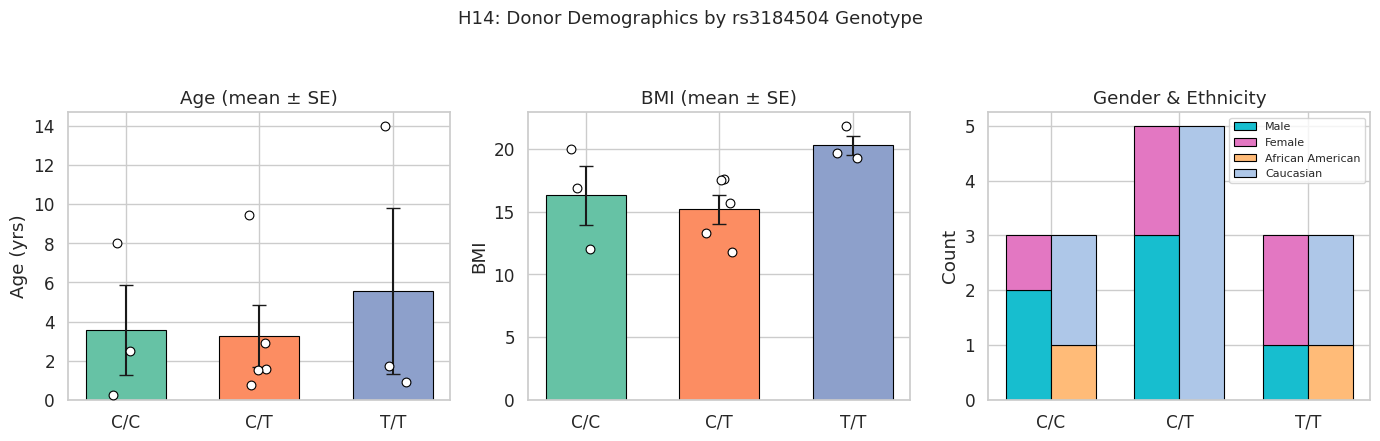

In [14]:
# Donor demographics summary for the 11 samples in this analysis
clin = load_clinical()
h14_samples = set(results["Sample"].unique())
clin_h14 = clin[clin["Sample"].isin(h14_samples)].copy()
clin_h14["Genotype"] = pd.Categorical(clin_h14["Genotype"], categories=GENO_ORDER, ordered=True)
clin_h14 = clin_h14.sort_values(["Genotype", "Sample"]).reset_index(drop=True)

print(f"=== Donor Characteristics (n={len(clin_h14)}) ===\n")
display_cols = ["Sample", "Genotype", "Platform", "Age (yrs)", "Gender", "Ethnicity", "BMI"]
display(clin_h14[display_cols].astype({c: str for c in display_cols}).fillna("\u2014"))

# Summary table by genotype
summary_rows = []
for geno in GENO_ORDER:
    g = clin_h14[clin_h14["Genotype"] == geno]
    n = len(g)
    age = g["Age (yrs)"].dropna()
    bmi = g["BMI"].dropna()
    female_n = (g["Gender"] == "Female").sum()
    platforms = g["Platform"].value_counts().to_dict()
    summary_rows.append({
        "Genotype": geno, "n": n,
        "Age mean +/- SE": f"{age.mean():.1f} \u00b1 {age.sem():.1f}" if len(age) > 1 else ("\u2014" if len(age) == 0 else f"{age.mean():.1f}"),
        "Female n (%)": f"{female_n} ({100*female_n/n:.0f}%)" if n > 0 else "\u2014",
        "BMI mean +/- SE": f"{bmi.mean():.1f} \u00b1 {bmi.sem():.1f}" if len(bmi) > 1 else ("\u2014" if len(bmi) == 0 else f"{bmi.mean():.1f}"),
        "Phenocycler": platforms.get("Phenocycler", 0),
        "CODEX": platforms.get("CODEX", 0),
    })
demo_summary = pd.DataFrame(summary_rows)
print("\n=== Summary by Genotype ===\n")
display(demo_summary)

save_table(clin_h14[["Sample", "Genotype", "Platform", "Age (yrs)", "Gender",
                      "Ethnicity", "C-pep (ng/ml)", "HbA1c", "BMI"]], "H14_donor_characteristics")

# --- Demographics figure ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# Panel 1: Age by genotype — bar with mean + SE + individual points
ax0 = axes[0]
age_stats = clin_h14.groupby("Genotype", observed=True)["Age (yrs)"].agg(["mean", "sem"])
age_stats = age_stats.reindex(GENO_ORDER)
bars = ax0.bar(range(len(GENO_ORDER)), age_stats["mean"], yerr=age_stats["sem"],
               capsize=5, color=[GENO_PALETTE[g] for g in GENO_ORDER],
               edgecolor="black", linewidth=0.8, width=0.6, error_kw={"lw": 1.5})
for i, geno in enumerate(GENO_ORDER):
    vals = clin_h14.loc[clin_h14["Genotype"] == geno, "Age (yrs)"].dropna()
    ax0.scatter(np.full(len(vals), i) + np.random.uniform(-0.12, 0.12, len(vals)),
                vals, s=40, c="white", edgecolors="black", linewidths=0.8, zorder=5)
ax0.set_xticks(range(len(GENO_ORDER)))
ax0.set_xticklabels(GENO_ORDER)
ax0.set_ylabel("Age (yrs)")
ax0.set_title("Age (mean \u00b1 SE)")

# Panel 2: BMI by genotype — bar with mean + SE + individual points
ax1 = axes[1]
bmi_stats = clin_h14.groupby("Genotype", observed=True)["BMI"].agg(["mean", "sem"])
bmi_stats = bmi_stats.reindex(GENO_ORDER)
ax1.bar(range(len(GENO_ORDER)), bmi_stats["mean"], yerr=bmi_stats["sem"],
        capsize=5, color=[GENO_PALETTE[g] for g in GENO_ORDER],
        edgecolor="black", linewidth=0.8, width=0.6, error_kw={"lw": 1.5})
for i, geno in enumerate(GENO_ORDER):
    vals = clin_h14.loc[clin_h14["Genotype"] == geno, "BMI"].dropna()
    ax1.scatter(np.full(len(vals), i) + np.random.uniform(-0.12, 0.12, len(vals)),
                vals, s=40, c="white", edgecolors="black", linewidths=0.8, zorder=5)
ax1.set_xticks(range(len(GENO_ORDER)))
ax1.set_xticklabels(GENO_ORDER)
ax1.set_ylabel("BMI")
ax1.set_title("BMI (mean \u00b1 SE)")

# Panel 3: Gender + Ethnicity (grouped stacked bar)
ax2 = axes[2]
gender_counts = clin_h14.groupby(["Genotype", "Gender"], observed=True).size().unstack(fill_value=0)
gender_counts = gender_counts.reindex(GENO_ORDER)
eth_counts = clin_h14.groupby(["Genotype", "Ethnicity"], observed=True).size().unstack(fill_value=0)
eth_counts = eth_counts.reindex(GENO_ORDER)

x = np.arange(len(GENO_ORDER))
bar_w = 0.35

# Gender bars (left)
bottom_g = np.zeros(len(GENO_ORDER))
gender_colors = {"Female": "#e377c2", "Male": "#17becf"}
for gender in ["Male", "Female"]:
    if gender in gender_counts.columns:
        vals = gender_counts[gender].values.astype(float)
        ax2.bar(x - bar_w/2, vals, bar_w, bottom=bottom_g,
                color=gender_colors[gender], edgecolor="black", linewidth=0.8,
                label=gender)
        bottom_g += vals

# Ethnicity bars (right)
bottom_e = np.zeros(len(GENO_ORDER))
eth_colors = {"Caucasian": "#aec7e8", "African American": "#ffbb78"}
for eth in sorted(eth_counts.columns):
    vals = eth_counts[eth].values.astype(float)
    color = eth_colors.get(eth, "#cccccc")
    ax2.bar(x + bar_w/2, vals, bar_w, bottom=bottom_e,
            color=color, edgecolor="black", linewidth=0.8,
            label=eth)
    bottom_e += vals

ax2.set_xticks(x)
ax2.set_xticklabels(GENO_ORDER)
ax2.set_ylabel("Count")
ax2.set_title("Gender & Ethnicity")
ax2.legend(fontsize=8, loc="upper right", ncol=1)

fig.suptitle("H14: Donor Demographics by rs3184504 Genotype", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.93])
save_figure(fig, "H14_donor_demographics")
plt.show()

---
### Region Morphometry by Genotype

Compare the **cell-derived region structure** across genotypes in the cropped windows.
Metrics computed from KDE-derived polygons (not individual follicles):
- **Region area** (mm²) — total polygon area per region per image
- **Polygon count** — number of distinct polygons
- **Mean polygon size** (mm²)
- **WP composition** — Follicle fraction of WhitePulp, Follicle/PALS area ratio

=== Region Morphometry Summary ===



,Sample,Genotype,Platform,Follicle_area_mm2,Follicle_n_polys,Follicle_mean_poly_mm2,PALS_area_mm2,PALS_n_polys,PALS_mean_poly_mm2,WP_area_mm2,WP_n_polys,Follicle_frac_of_WP,Follicle_PALS_ratio
0,1901HBMP004,T/T,CODEX,2.9378,9,0.3264,0.0551,3,0.0184,2.9805,8,0.9857,53.3327
1,HDL011,C/C,Phenocycler,12.8905,96,0.1343,1.3242,8,0.1655,14.2147,89,0.9068,9.7346
2,HDL043,C/T,Phenocycler,27.9072,95,0.2938,4.2094,34,0.1238,32.1166,102,0.8689,6.6298
3,HDL052,C/T,Phenocycler,5.0491,26,0.1942,0.0930,4,0.0232,5.1421,26,0.9819,54.3113
4,HDL053,C/C,Phenocycler,26.0947,164,0.1591,5.7172,61,0.0937,31.8119,188,0.8203,4.5643
5,HDL055,C/C,Phenocycler,19.1593,124,0.1545,2.6503,22,0.1205,21.6766,123,0.8839,7.2291
6,HDL063,T/T,Phenocycler,28.8235,267,0.1080,3.0117,35,0.0860,31.8352,263,0.9054,9.5706
7,HDL070,C/T,Phenocycler,14.4672,89,0.1626,2.5728,34,0.0757,17.0399,94,0.8490,5.6232
8,HDL073,T/T,CODEX,3.9077,31,0.1261,0.1967,5,0.0393,4.1044,28,0.9521,19.8627
9,HDL079,C/T,Phenocycler,17.9408,150,0.1196,1.1647,21,0.0555,19.0825,145,0.9402,15.4032


Saved: analysis/tables/H14_region_morphometry.csv

=== Region Morphometry — Statistical Tests ===
                     Test                      Metric  Statistic        p Effect_Size
           Kruskal-Wallis         Follicle Area (mm²)   0.678788 0.712202            
Mann-Whitney (C/C vs C/T)         Follicle Area (mm²)   8.000000 1.000000    r=-0.067
Mann-Whitney (C/C vs T/T)         Follicle Area (mm²)   6.000000 0.700000    r=-0.333
Mann-Whitney (C/T vs T/T)         Follicle Area (mm²)  10.000000 0.571429    r=-0.333
          Spearman dosage         Follicle Area (mm²)  -0.233550 0.489462  rho=-0.234
           Kruskal-Wallis      Follicle Polygon Count   1.527273 0.465969            
Mann-Whitney (C/C vs C/T)      Follicle Polygon Count  12.000000 0.250000    r=-0.600
Mann-Whitney (C/C vs T/T)      Follicle Polygon Count   6.000000 0.700000    r=-0.333
Mann-Whitney (C/T vs T/T)      Follicle Polygon Count   9.000000 0.785714    r=-0.200
          Spearman dosage      Follicle Po

Saved: analysis/figures/H14_region_morphometry_genotype.png


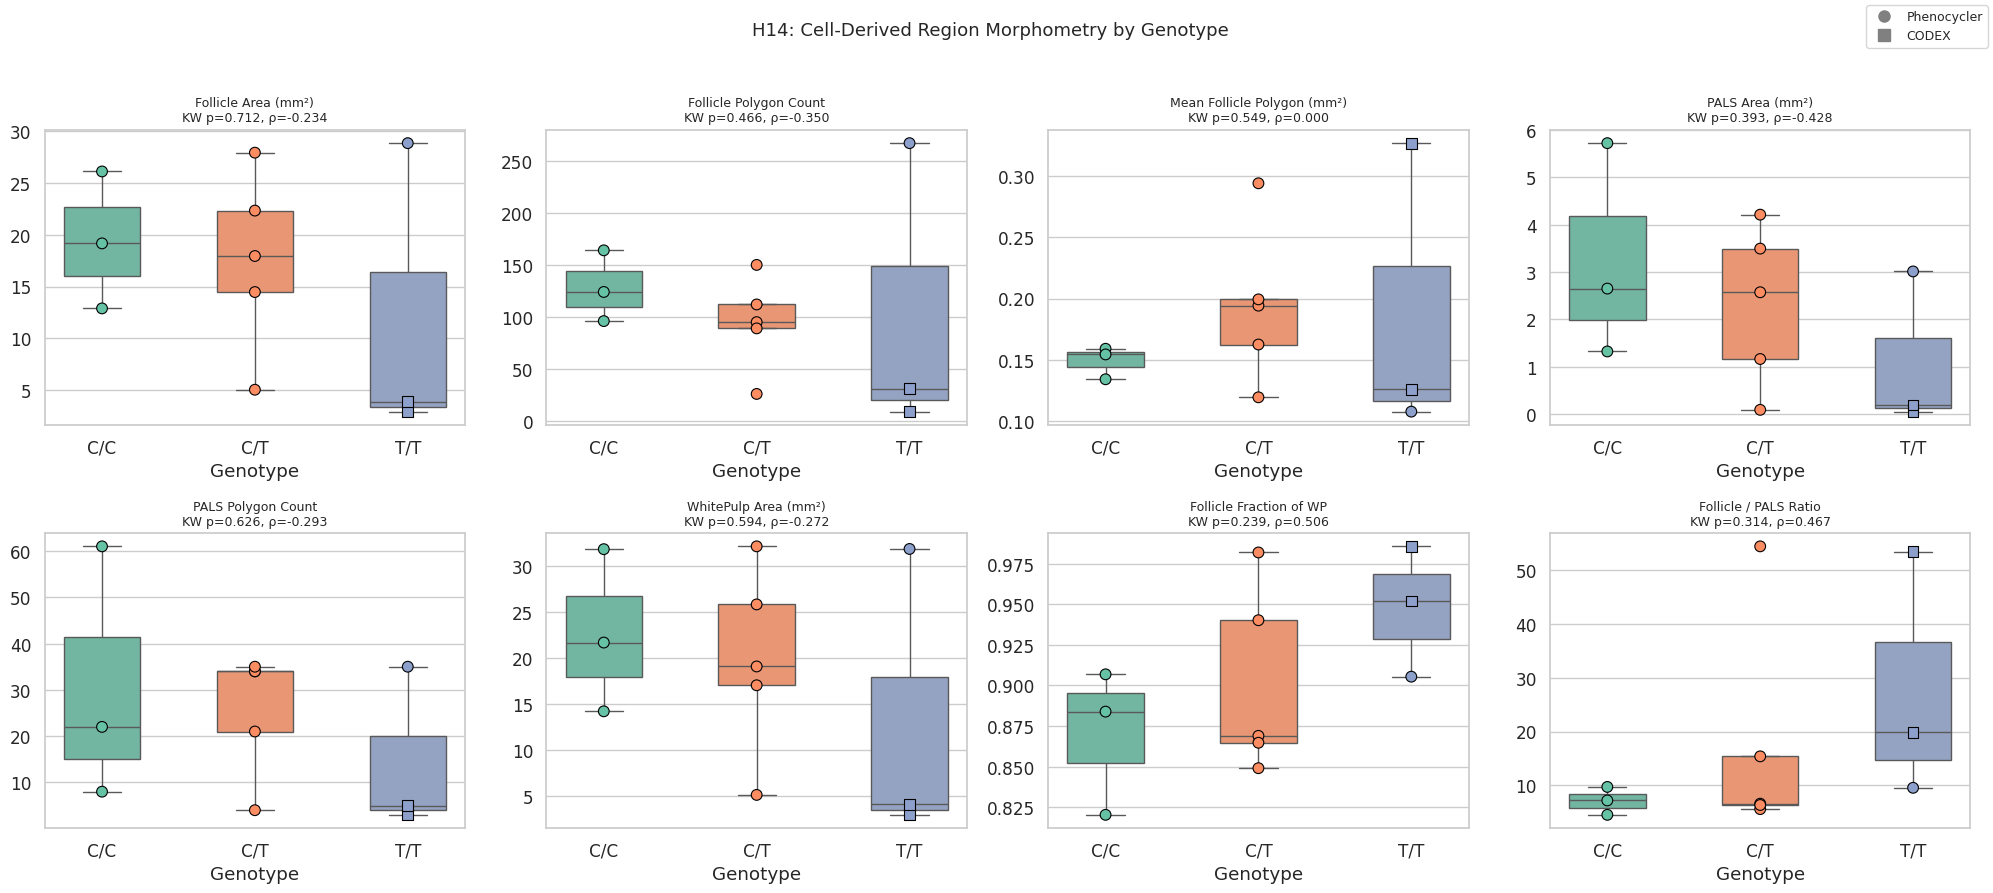

In [15]:
# Region morphometry — compare cell-derived regions between genotypes
morph_rows = []

for image in sorted(follicle_polys.keys()):
    sid = img_to_sample[image]
    geno = str(GENOTYPE_MAP.get(sid, "?"))
    platform = "CODEX" if sid in CODEX_SAMPLES else "Phenocycler"

    fol_areas = [p.area for p in follicle_polys[image]]
    pals_areas = [p.area for p in pals_polys[image]]
    wp_areas = [p.area for p in wp_polys[image]]

    fol_total = sum(fol_areas) if fol_areas else 0
    pals_total = sum(pals_areas) if pals_areas else 0
    wp_total = sum(wp_areas) if wp_areas else 0

    morph_rows.append({
        "Image": image, "Sample": sid, "Genotype": geno, "Platform": platform,
        # Follicle
        "Follicle_area_mm2": fol_total / 1e6,
        "Follicle_n_polys": len(fol_areas),
        "Follicle_mean_poly_mm2": (np.mean(fol_areas) / 1e6) if fol_areas else 0,
        # PALS
        "PALS_area_mm2": pals_total / 1e6,
        "PALS_n_polys": len(pals_areas),
        "PALS_mean_poly_mm2": (np.mean(pals_areas) / 1e6) if pals_areas else 0,
        # WhitePulp
        "WP_area_mm2": wp_total / 1e6,
        "WP_n_polys": len(wp_areas),
        # Composition
        "Follicle_frac_of_WP": fol_total / wp_total if wp_total > 0 else np.nan,
        "Follicle_PALS_ratio": fol_total / pals_total if pals_total > 0 else np.nan,
    })

region_morph = pd.DataFrame(morph_rows)
region_morph["Genotype"] = pd.Categorical(region_morph["Genotype"],
                                           categories=GENO_ORDER, ordered=True)

print("=== Region Morphometry Summary ===\n")
display(region_morph.drop(columns=["Image"]).round(4))

save_table(region_morph, "H14_region_morphometry")

# --- Statistical tests on each metric ---
morph_metrics = [
    ("Follicle_area_mm2", "Follicle Area (mm\u00b2)"),
    ("Follicle_n_polys", "Follicle Polygon Count"),
    ("Follicle_mean_poly_mm2", "Mean Follicle Polygon (mm\u00b2)"),
    ("PALS_area_mm2", "PALS Area (mm\u00b2)"),
    ("PALS_n_polys", "PALS Polygon Count"),
    ("WP_area_mm2", "WhitePulp Area (mm\u00b2)"),
    ("Follicle_frac_of_WP", "Follicle Fraction of WP"),
    ("Follicle_PALS_ratio", "Follicle / PALS Ratio"),
]

morph_stats = []
for col, label in morph_metrics:
    morph_stats.append(full_stats_table(region_morph, col, label))
morph_stats_df = pd.concat(morph_stats, ignore_index=True)

print("\n=== Region Morphometry — Statistical Tests ===")
print(morph_stats_df.to_string(index=False))

save_table(morph_stats_df, "H14_region_morphometry_stats")

# --- Figure: 2 rows x 4 cols ---
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
markers_shape = {"Phenocycler": "o", "CODEX": "s"}

for ax, (col, label) in zip(axes.flat, morph_metrics):
    sns.boxplot(data=region_morph, x="Genotype", y=col,
                order=GENO_ORDER, palette=GENO_PALETTE, ax=ax, width=0.5, fliersize=0)
    for plat, mkr in markers_shape.items():
        sub = region_morph[region_morph["Platform"] == plat]
        x_pos = sub["Genotype"].astype(str).map({g: i for i, g in enumerate(GENO_ORDER)})
        ax.scatter(x_pos, sub[col], marker=mkr, s=60,
                   c=[GENO_PALETTE[g] for g in sub["Genotype"].astype(str)],
                   edgecolors="black", linewidths=0.8, zorder=5)
    # Annotate with KW p-value
    st = morph_stats_df[(morph_stats_df["Metric"] == label) &
                         (morph_stats_df["Test"] == "Kruskal-Wallis")]
    kw_p = st["p"].values[0] if len(st) else np.nan
    rho_row = morph_stats_df[(morph_stats_df["Metric"] == label) &
                              (morph_stats_df["Test"] == "Spearman dosage")]
    rho = rho_row["Statistic"].values[0] if len(rho_row) else np.nan
    ax.set_title(f"{label}\nKW p={kw_p:.3f}, \u03c1={rho:.3f}", fontsize=9)
    ax.set_ylabel("")

fig.legend(handles=[plt.Line2D([], [], marker="o", color="gray", ls="", label="Phenocycler", ms=8),
                     plt.Line2D([], [], marker="s", color="gray", ls="", label="CODEX", ms=8)],
           loc="upper right", fontsize=9)
fig.suptitle("H14: Cell-Derived Region Morphometry by Genotype", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, "H14_region_morphometry_genotype")
plt.show()

GENOTYPE ANALYSIS — Vessel Metrics by Region


Saved: analysis/figures/H14_genotype_vessel_metrics.png


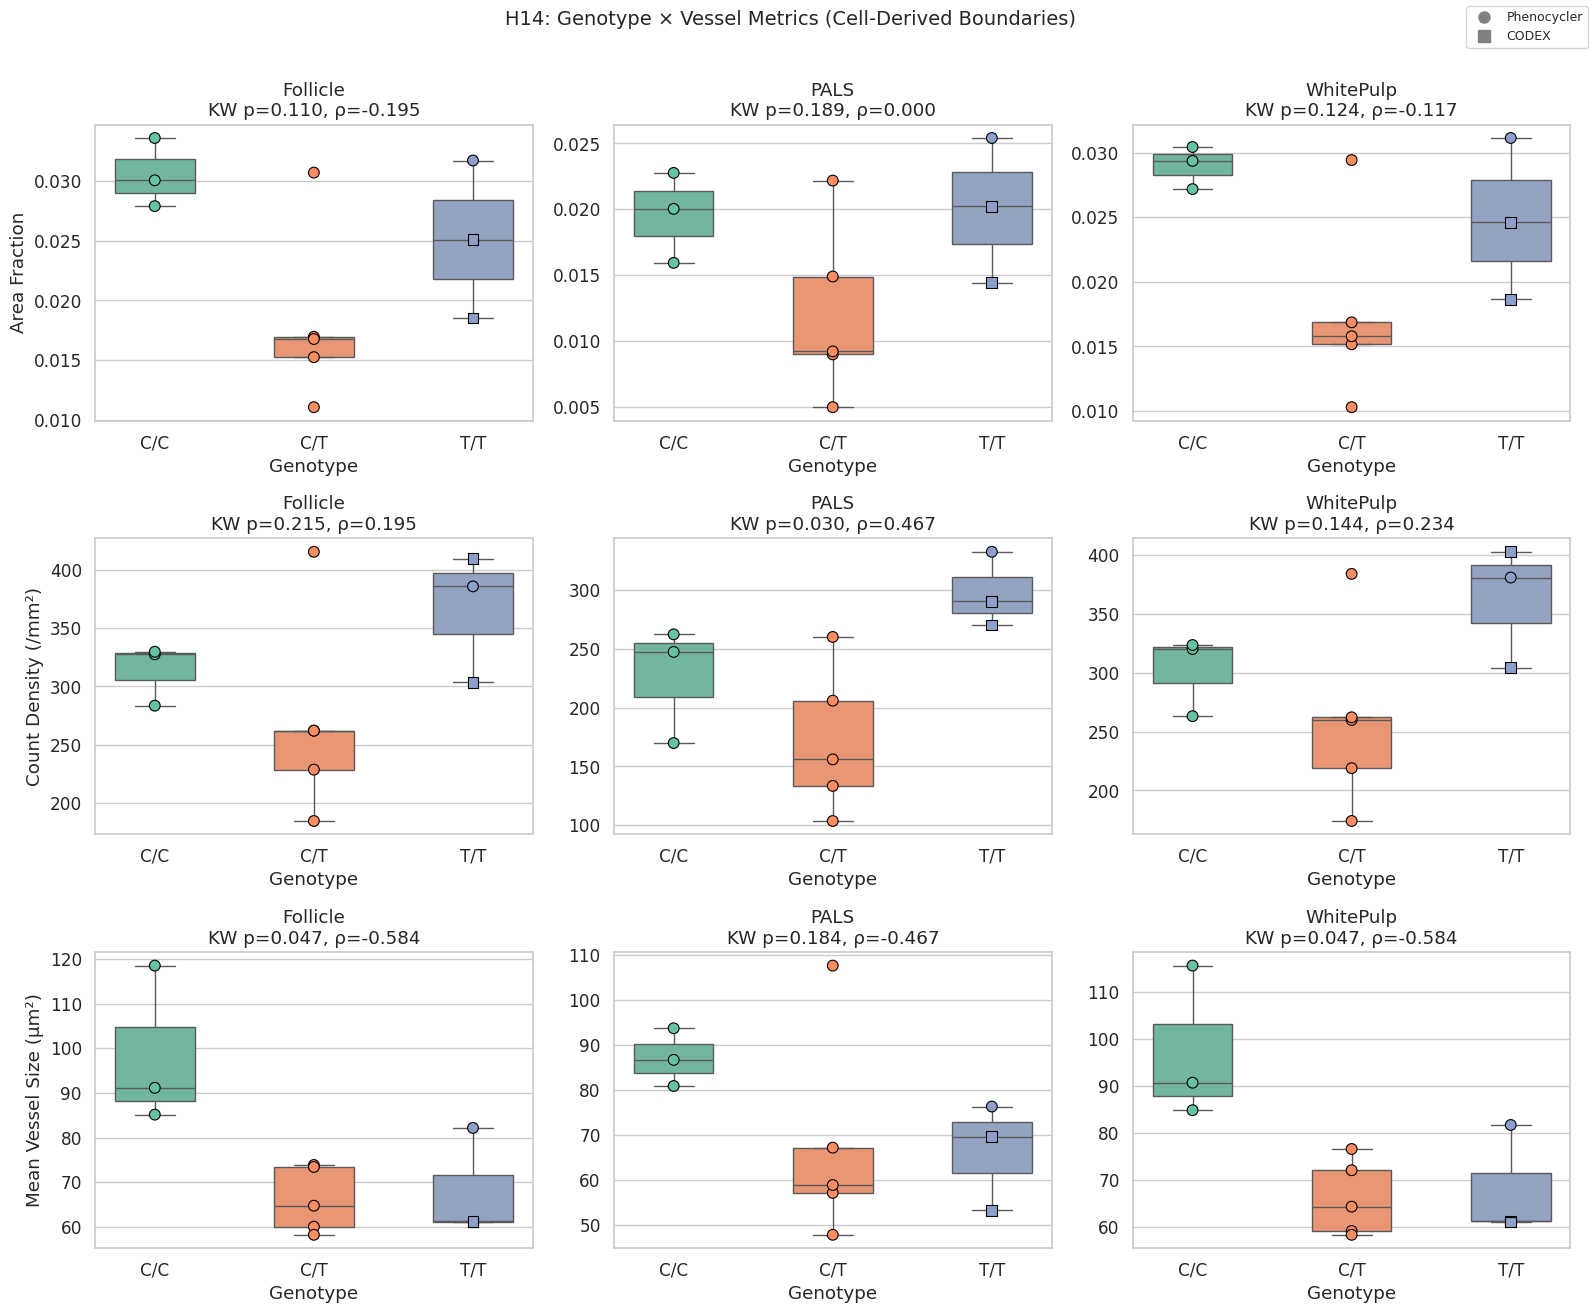

Saved: analysis/tables/H14_genotype_stats.csv

Statistical results:
                     Test                           Metric  Statistic        p Effect_Size
           Kruskal-Wallis    Follicle_Vessel_Area_Fraction   4.412121 0.110134            
Mann-Whitney (C/C vs C/T)    Follicle_Vessel_Area_Fraction  13.000000 0.142857    r=-0.733
Mann-Whitney (C/C vs T/T)    Follicle_Vessel_Area_Fraction   7.000000 0.400000    r=-0.556
Mann-Whitney (C/T vs T/T)    Follicle_Vessel_Area_Fraction   2.000000 0.142857     r=0.733
          Spearman dosage    Follicle_Vessel_Area_Fraction  -0.194625 0.566336  rho=-0.195
           Kruskal-Wallis        PALS_Vessel_Area_Fraction   3.333333 0.188876            
Mann-Whitney (C/C vs C/T)        PALS_Vessel_Area_Fraction  13.000000 0.142857    r=-0.733
Mann-Whitney (C/C vs T/T)        PALS_Vessel_Area_Fraction   4.000000 1.000000     r=0.111
Mann-Whitney (C/T vs T/T)        PALS_Vessel_Area_Fraction   3.000000 0.250000     r=0.600
          Spearman dos

In [16]:
# Genotype analysis — three vessel metrics per region
print("=" * 70)
print("GENOTYPE ANALYSIS — Vessel Metrics by Region")
print("=" * 70)

markers_shape = {"Phenocycler": "o", "CODEX": "s"}
metrics = [
    ("Vessel_Area_Fraction", "Area Fraction"),
    ("Vessel_Density_per_mm2", "Count Density (/mm²)"),
    ("Mean_Vessel_Area_um2", "Mean Vessel Size (µm²)"),
]
regions = ["Follicle", "PALS", "WhitePulp"]

all_stats = []
fig, axes = plt.subplots(len(metrics), len(regions), figsize=(16, 13))

for row, (metric_col, metric_label) in enumerate(metrics):
    for col, region in enumerate(regions):
        ax = axes[row, col]
        rd = results[results["Region"] == region].copy()
        if rd.empty:
            ax.set_title(f"{region}\n(no data)")
            continue
        stats = full_stats_table(rd, metric_col, f"{region}_{metric_col}")
        all_stats.append(stats)

        sns.boxplot(data=rd, x="Genotype", y=metric_col,
                    order=GENO_ORDER, palette=GENO_PALETTE, ax=ax, width=0.5, fliersize=0)
        for plat, mkr in markers_shape.items():
            sub = rd[rd["Platform"] == plat]
            x_pos = sub["Genotype"].astype(str).map({g: i for i, g in enumerate(GENO_ORDER)})
            ax.scatter(x_pos, sub[metric_col], marker=mkr, s=60,
                       c=[GENO_PALETTE[g] for g in sub["Genotype"].astype(str)],
                       edgecolors="black", linewidths=0.8, zorder=5)
        kw_p = stats[stats["Test"] == "Kruskal-Wallis"]["p"].values[0]
        rho_row = stats[stats["Test"] == "Spearman dosage"]
        rho = rho_row["Statistic"].values[0] if len(rho_row) else np.nan
        ax.set_title(f"{region}\nKW p={kw_p:.3f}, \u03c1={rho:.3f}")
        ax.set_ylabel(metric_label if col == 0 else "")

fig.legend(handles=[plt.Line2D([], [], marker="o", color="gray", ls="", label="Phenocycler", ms=8),
                     plt.Line2D([], [], marker="s", color="gray", ls="", label="CODEX", ms=8)],
           loc="upper right", fontsize=9)
fig.suptitle("H14: Genotype × Vessel Metrics (Cell-Derived Boundaries)", fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, "H14_genotype_vessel_metrics")
plt.show()

stats_all = pd.concat(all_stats, ignore_index=True)
save_table(stats_all, "H14_genotype_stats")
print("\nStatistical results:")
print(stats_all.to_string(index=False))

In [17]:
# Platform consistency — Mann-Whitney CODEX vs Phenocycler (all metrics)
print("Platform consistency — Mann-Whitney (CODEX vs Phenocycler):\n")
platform_rows = []
for region in ["Follicle", "PALS", "WhitePulp"]:
    rd = results[results["Region"] == region]
    for metric_col, metric_label in [("Vessel_Area_Fraction", "Area Fraction"),
                                      ("Vessel_Density_per_mm2", "Count Density"),
                                      ("Mean_Vessel_Area_um2", "Mean Vessel Size")]:
        codex = rd.loc[rd["Platform"] == "CODEX", metric_col].dropna()
        pc = rd.loc[rd["Platform"] == "Phenocycler", metric_col].dropna()
        if len(codex) < 1 or len(pc) < 1:
            platform_rows.append({"Region": region, "Metric": metric_label,
                                   "U": np.nan, "p": np.nan, "r": np.nan,
                                   "n_CODEX": len(codex), "n_PC": len(pc)})
            continue
        u, p = mannwhitneyu(codex, pc, alternative="two-sided")
        r = 1 - 2 * u / (len(codex) * len(pc))
        platform_rows.append({"Region": region, "Metric": metric_label,
                               "U": u, "p": p, "r": r,
                               "n_CODEX": len(codex), "n_PC": len(pc),
                               "CODEX_med": codex.median(), "PC_med": pc.median()})
        print(f"  {region:10s} {metric_label:18s}: U={u:.1f}, p={p:.4f}, r={r:.3f} "
              f"(CODEX={codex.median():.2f}, PC={pc.median():.2f})")

platform_df = pd.DataFrame(platform_rows)
save_table(platform_df, "H14_platform_check")

Platform consistency — Mann-Whitney (CODEX vs Phenocycler):

  Follicle   Area Fraction     : U=8.0, p=0.9091, r=0.111 (CODEX=0.02, PC=0.03)
  Follicle   Count Density     : U=13.0, p=0.4364, r=-0.444 (CODEX=356.51, PC=283.47)
  Follicle   Mean Vessel Size  : U=4.0, p=0.3273, r=0.556 (CODEX=61.19, PC=73.86)
  PALS       Area Fraction     : U=9.0, p=1.0000, r=0.000 (CODEX=0.02, PC=0.02)
  PALS       Count Density     : U=16.0, p=0.1455, r=-0.778 (CODEX=280.42, PC=205.99)
  PALS       Mean Vessel Size  : U=5.0, p=0.4364, r=0.444 (CODEX=61.49, PC=76.36)
  WhitePulp  Area Fraction     : U=8.0, p=0.9091, r=0.111 (CODEX=0.02, PC=0.03)
  WhitePulp  Count Density     : U=14.0, p=0.3273, r=-0.556 (CODEX=353.69, PC=263.12)
  WhitePulp  Mean Vessel Size  : U=4.0, p=0.3273, r=0.556 (CODEX=61.14, PC=76.58)
Saved: analysis/tables/H14_platform_check.csv


  CD20 Percentile = 80...


  CD20 Percentile = 85...


  CD20 Percentile = 90...


  CD20 Percentile = 95...



Sensitivity summary (means across images):
            BW_mean  n_follicles  Follicle_area_mm2  Vessel_Area_Fraction  \
Percentile                                                                  
80          37.7288     156.1818            28.2730                0.0273   
85          38.2759     128.8182            21.9011                0.0261   
90          40.5836     105.6364            16.4945                0.0233   
95          48.5324      88.6364            11.4581                0.0183   

            Vessel_Density  Mean_Vessel_Size  
Percentile                                    
80                336.2380           79.4682  
85                329.6891           77.4816  
90                306.4186           75.4052  
95                259.4302           71.0884  


Saved: analysis/figures/H14_sensitivity_analysis.png
Saved: analysis/tables/H14_percentile_sensitivity.csv


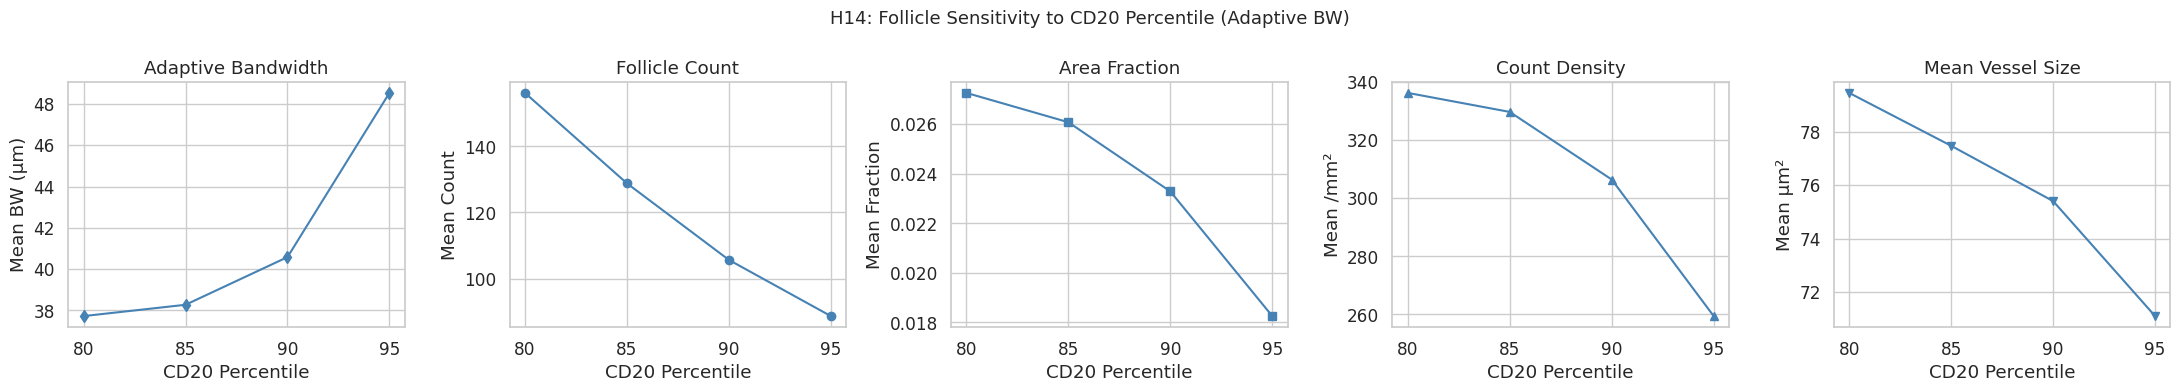

In [18]:
# Sensitivity: sweep CD20 percentile using stored raw cell data
# Each percentile changes the positive-cell set, so adaptive BW is recomputed.
percentiles = [80, 85, 90, 95]
sens_rows = []

for pctl in percentiles:
    print(f"  CD20 Percentile = {pctl}...", flush=True)
    for image in sorted(raw_cell_data.keys()):
        sid = img_to_sample[image]
        data = raw_cell_data[image]  # (N, 4): x, y, cd20, cd3e

        cd20_vals = data[:, 2]
        cd20_thr = np.nanpercentile(cd20_vals, pctl)
        cd20_high = data[cd20_vals > cd20_thr, :2]
        all_xy = data[:, :2]

        # Adaptive bandwidth for this percentile's positive set
        bw = adaptive_bandwidth(cd20_high) if len(cd20_high) > BW_K + 1 else 50
        kde_pad = 2 * bw

        x_range = (all_xy[:, 0].min() - kde_pad, all_xy[:, 0].max() + kde_pad)
        y_range = (all_xy[:, 1].min() - kde_pad, all_xy[:, 1].max() + kde_pad)

        if len(cd20_high) > 10:
            dens, xe, ye = compute_marker_kde(
                cd20_high, x_range, y_range, grid_spacing=GRID_SPACING, bandwidth=bw)
            fol_p = extract_region_polygons(
                dens, CD20_THRESHOLD_FRAC, GRID_SPACING, xe[0], ye[0], min_area=MIN_AREA_UM2)
        else:
            fol_p = []

        fol_area_um2 = sum(p.area for p in fol_p)
        fol_area_mm2 = fol_area_um2 / 1e6

        img_v = vessels_crop[vessels_crop["Image"] == image]
        v_count = 0
        v_area_frac = 0.0
        v_density = 0.0
        mean_v_size = 0.0
        if not img_v.empty and fol_p:
            vc = img_v[[X_COL, Y_COL]].values
            va = img_v["Area µm^2"].values
            vlabels = assign_objects_to_polygons(vc, {"Follicle": fol_p})
            in_fol = vlabels == "Follicle"
            v_count = int(in_fol.sum())
            v_area_inside = float(va[in_fol].sum())
            v_area_frac = v_area_inside / fol_area_um2 if fol_area_um2 > 0 else 0
            v_density = v_count / fol_area_mm2 if fol_area_mm2 > 0 else 0
            mean_v_size = v_area_inside / v_count if v_count > 0 else 0

        sens_rows.append({"Percentile": pctl, "Sample": sid, "BW_used": bw,
                           "n_follicles": len(fol_p), "Follicle_area_mm2": fol_area_mm2,
                           "Vessel_Count": v_count,
                           "Vessel_Area_Fraction": v_area_frac,
                           "Vessel_Density_per_mm2": v_density,
                           "Mean_Vessel_Area_um2": mean_v_size})

sens_df = pd.DataFrame(sens_rows)
sens_df["Genotype"] = sens_df["Sample"].map(GENOTYPE_MAP)
print("\nSensitivity summary (means across images):")
print(sens_df.groupby("Percentile").agg(
    BW_mean=("BW_used", "mean"),
    n_follicles=("n_follicles", "mean"),
    Follicle_area_mm2=("Follicle_area_mm2", "mean"),
    Vessel_Area_Fraction=("Vessel_Area_Fraction", "mean"),
    Vessel_Density=("Vessel_Density_per_mm2", "mean"),
    Mean_Vessel_Size=("Mean_Vessel_Area_um2", "mean"),
).round(4))

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col, ylabel, title, marker in [
    (axes[0], "BW_used", "Mean BW (µm)", "Adaptive Bandwidth", "d-"),
    (axes[1], "n_follicles", "Mean Count", "Follicle Count", "o-"),
    (axes[2], "Vessel_Area_Fraction", "Mean Fraction", "Area Fraction", "s-"),
    (axes[3], "Vessel_Density_per_mm2", "Mean /mm²", "Count Density", "^-"),
    (axes[4], "Mean_Vessel_Area_um2", "Mean µm²", "Mean Vessel Size", "v-"),
]:
    means = sens_df.groupby("Percentile")[col].mean()
    ax.plot(means.index, means.values, marker, color="steelblue")
    ax.set_xlabel("CD20 Percentile"); ax.set_ylabel(ylabel); ax.set_title(title)

fig.suptitle("H14: Follicle Sensitivity to CD20 Percentile (Adaptive BW)", fontsize=13)
plt.tight_layout()
save_figure(fig, "H14_sensitivity_analysis")
save_table(sens_df, "H14_percentile_sensitivity")
plt.show()

## Summary

**H14 v2** replaces Otsu thresholding with **per-image percentile thresholding**
(top 10%, p90), selecting only strongly-expressing cells. This prevents diffusely
distributed moderate-expressors from inflating region boundaries (especially PALS).
KDE bandwidth is **adaptive per image** based on k-nearest-neighbor distances of
marker-positive cells — images with tightly clustered marker expression get sharper
boundaries.

### Key Changes from v1

| Aspect | v1 | v2 |
|--------|----|----|
| Thresholding | Otsu (platform-sensitive) | Percentile p90 (platform-invariant) |
| Bandwidth | Fixed 75 um (over-smoothed) | Adaptive per-image from 5-NN distances |
| Crop | 5000x5000 square | 5000x3000 rectangle |
| Metric | Vessel count / area | 3 metrics: area fraction, count density, mean vessel size |
| LargeVessel | Not handled | Excluded from denominator (arterioles share CD31/CD34) |
| Data file | AnnotationsFinalwith079.csv | AnnotationsFinal.csv (corrected 1901 LargeVessels) |
| Samples | 10 | 11 (adds HDL079 as C/T) |
| Regions | Follicle only | Follicle, PALS, WhitePulp |
| Edge artifacts | Tissue mask erosion | KDE grid padding (2xBW per image) |

### Vessel Metrics (3-metric decomposition)

| Metric | Formula | Biological meaning |
|--------|---------|-------------------|
| **Vessel Area Fraction** | SV_area / effective_area | Total vascular coverage (dimensionless) |
| **Vessel Count Density** | SV_count / effective_area_mm² | Vessel frequency per unit area |
| **Mean Vessel Size** | SV_area / SV_count | Individual vessel caliber (µm²) |

Area fraction = count density × mean size. Decomposing allows distinguishing whether
genotype differences arise from more/fewer vessels vs larger/smaller vessels.

### Adaptive Bandwidth
`BW = NND_SCALE x median(5th-NN distance)`, clamped to [25, 100] um.
Dense marker clusters -> small NND -> tight bandwidth -> sharper boundaries.

### Verification Checklist
1. All 11 samples produce follicle and PALS polygons
2. Marker enrichment: CD20-high cells >50% inside Follicle; CD3e-high >30% inside PALS
3. Vessel area fraction in sensible range (0.01-0.10)
4. Sensitivity analysis stable across percentile thresholds (80-95)
5. Visual inspection of masks confirms reasonable boundaries
6. LargeVessel exclusion verified — red markers on verification figure
7. Cross-check table confirms 0 discrepancy between original and recomputed fractions